In [2]:
!pip -q install kaggle scikit-learn joblib

import os, re, json, time, random, zipfile, subprocess, sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import TensorDataset, DataLoader

from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
import joblib

SEED = 2028
EPOCHS = 100
BATCH_SIZE = 128
LR = 1e-3
RAW_N = 2560

TRAIN_BEARINGS = [
    "Bearing1_1", "Bearing1_2", "Bearing2_1",
    "Bearing2_2", "Bearing3_1", "Bearing3_2"
]

TEST_BEARINGS = [
    "Bearing1_3", "Bearing1_4", "Bearing1_5",
    "Bearing1_7", "Bearing2_3", "Bearing2_6"
]

DATA_DIR = Path("/content/femto_data")
OUT = Path("/content/bearing_rul_cbam_only")
DATA_DIR.mkdir(parents=True, exist_ok=True)
OUT.mkdir(parents=True, exist_ok=True)

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

torch.set_num_threads(min(4, os.cpu_count() or 2))
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", DEVICE)
if DEVICE.type == "cuda":
    print(torch.cuda.get_device_name(0))

Device: cpu


In [3]:
from google.colab import files

kaggle_json = Path.home() / ".kaggle" / "kaggle.json"
kaggle_json.parent.mkdir(parents=True, exist_ok=True)

if not kaggle_json.exists():
    uploaded = files.upload()
    if "kaggle.json" not in uploaded:
        raise FileNotFoundError("Upload your Kaggle API token as kaggle.json")
    kaggle_json.write_bytes(uploaded["kaggle.json"])
    kaggle_json.chmod(0o600)

if not list(DATA_DIR.rglob("Learning_set")) or not list(DATA_DIR.rglob("Full_Test_Set")):
    subprocess.run([
        "kaggle", "datasets", "download",
        "-d", "alanhabrony/ieee-phm-2012-data-challenge",
        "-p", str(DATA_DIR)
    ], check=True)

for z in DATA_DIR.glob("*.zip"):
    with zipfile.ZipFile(z) as f:
        f.extractall(DATA_DIR)

learning_dirs = [p for p in DATA_DIR.rglob("Learning_set") if p.is_dir()]
full_dirs = [p for p in DATA_DIR.rglob("Full_Test_Set") if p.is_dir()]

LEARNING_DIR = next((p for p in learning_dirs if all((p / b).is_dir() for b in TRAIN_BEARINGS)), None)
FULL_TEST_DIR = next((p for p in full_dirs if all((p / b).is_dir() for b in TEST_BEARINGS)), None)

if LEARNING_DIR is None or FULL_TEST_DIR is None:
    raise FileNotFoundError("Could not find the expected Learning_set and Full_Test_Set folders")

print("Learning set:", LEARNING_DIR)
print("Full test set:", FULL_TEST_DIR)

Saving kaggle.json to kaggle.json
Learning set: /content/femto_data/ieee-phm-2012-data-challenge-dataset-master/Learning_set
Full test set: /content/femto_data/ieee-phm-2012-data-challenge-dataset-master/Full_Test_Set


In [4]:
def read_signal(path):
    try:
        x = np.loadtxt(path, delimiter=",", dtype=np.float32)
    except Exception:
        x = pd.read_csv(path, header=None, sep=None, engine="python").to_numpy(dtype=np.float32)

    if x.ndim == 1:
        x = x.reshape(1, -1)
    if x.shape[1] < 2:
        raise ValueError(f"Bad CSV shape in {path}: {x.shape}")

    sig = x[:, -2].astype(np.float64)
    sig = sig[np.isfinite(sig)]
    if len(sig) != RAW_N:
        raise ValueError(f"Expected {RAW_N} samples in {path}, got {len(sig)}")
    return sig


def get_files(folder):
    paths = list(Path(folder).rglob("acc_*.csv"))
    return sorted(paths, key=lambda p: int(re.search(r"acc_(\d+)", p.name).group(1)))


def make_spectra(folder):
    paths = get_files(folder)
    if not paths:
        raise FileNotFoundError(folder)

    out = []
    for path in paths:
        x = read_signal(path)
        x = x - x.mean()
        a = np.abs(np.fft.rfft(x)).astype(np.float32) / len(x)
        if len(a) > 2:
            a[1:-1] *= 2
        out.append(a)
    return np.asarray(out, dtype=np.float32)

train_spectra, train_labels = {}, {}
test_spectra, test_labels = {}, {}

for name in TRAIN_BEARINGS:
    x = make_spectra(LEARNING_DIR / name)
    train_spectra[name] = x
    train_labels[name] = np.linspace(1, 0, len(x), dtype=np.float32)
    print(name, x.shape)

for name in TEST_BEARINGS:
    x = make_spectra(FULL_TEST_DIR / name)
    test_spectra[name] = x
    test_labels[name] = np.linspace(1, 0, len(x), dtype=np.float32)
    print(name, x.shape)

print("FFT bins:", next(iter(train_spectra.values())).shape[1])

Bearing1_1 (2803, 1281)
Bearing1_2 (871, 1281)
Bearing2_1 (911, 1281)
Bearing2_2 (797, 1281)
Bearing3_1 (515, 1281)
Bearing3_2 (1637, 1281)
Bearing1_3 (2375, 1281)
Bearing1_4 (1428, 1281)
Bearing1_5 (2463, 1281)
Bearing1_7 (2259, 1281)
Bearing2_3 (1955, 1281)
Bearing2_6 (701, 1281)
FFT bins: 1281


In [5]:
X_raw = np.concatenate([train_spectra[n] for n in TRAIN_BEARINGS])
y_train = np.concatenate([train_labels[n] for n in TRAIN_BEARINGS])

scaler = StandardScaler()
X_train = scaler.fit_transform(X_raw).astype(np.float32)
X_train = np.nan_to_num(X_train)

X_test = {}
for name in TEST_BEARINGS:
    X_test[name] = np.nan_to_num(
        scaler.transform(test_spectra[name]).astype(np.float32)
    )

train_ds = TensorDataset(torch.from_numpy(X_train), torch.from_numpy(y_train))
train_loader = DataLoader(
    train_ds, batch_size=BATCH_SIZE, shuffle=True,
    num_workers=0, pin_memory=(DEVICE.type == "cuda")
)

print("Training samples:", len(train_ds))
print("Input dimension:", X_train.shape[1])
print("Target range:", y_train.min(), y_train.max())

Training samples: 7534
Input dimension: 1281
Target range: 0.0 1.0


In [6]:
class CBAM1D(nn.Module):
    def __init__(self, channels=64, reduction=16, kernel=7):
        super().__init__()
        hidden = max(channels // reduction, 1)
        self.mlp = nn.Sequential(
            nn.Linear(channels, hidden),
            nn.ReLU(inplace=True),
            nn.Linear(hidden, channels)
        )
        self.spatial = nn.Conv1d(2, 1, kernel, padding=kernel // 2, bias=False)

    def forward(self, x):
        avg = x.mean(-1)
        mx = x.max(-1).values
        cw = torch.sigmoid(self.mlp(avg) + self.mlp(mx)).unsqueeze(-1)
        x = x * cw
        s = torch.cat([x.mean(1, keepdim=True), x.max(1, keepdim=True).values], dim=1)
        return x * torch.sigmoid(self.spatial(s))


class CBAMCNNLSTM(nn.Module):
    def __init__(self, input_len=1281):
        super().__init__()
        self.conv1 = nn.Conv1d(1, 16, 32, stride=2)
        self.bn1 = nn.BatchNorm1d(16)
        self.conv2 = nn.Conv1d(16, 32, 10)
        self.bn2 = nn.BatchNorm1d(32)
        self.conv3 = nn.Conv1d(32, 64, 10)
        self.bn3 = nn.BatchNorm1d(64)
        self.pool = nn.MaxPool1d(2, 2)
        self.cbam = CBAM1D(64, 16, 7)
        self.lstm = nn.LSTM(64, 128, num_layers=2, batch_first=True)
        self.fc = nn.Linear(128, 1)

    def forward(self, x):
        x = x.unsqueeze(1)
        x = self.pool(F.relu(self.bn1(self.conv1(x))))
        x = self.pool(F.relu(self.bn2(self.conv2(x))))
        x = self.cbam(F.relu(self.bn3(self.conv3(x))))
        x = self.pool(x).transpose(1, 2)
        x, _ = self.lstm(x)
        return torch.sigmoid(self.fc(x[:, -1])).squeeze(-1)


model = CBAMCNNLSTM().to(DEVICE)
with torch.no_grad():
    shape = model(torch.zeros(4, X_train.shape[1], device=DEVICE)).shape
print("Output shape:", shape)
print("Parameters:", sum(p.numel() for p in model.parameters()))
assert shape == (4,)
del model

Output shape: torch.Size([4])
Parameters: 258595


In [ ]:
torch.manual_seed(SEED)
if DEVICE.type == "cuda":
    torch.cuda.manual_seed_all(SEED)

model = CBAMCNNLSTM().to(DEVICE)
optimizer = torch.optim.Adam(model.parameters(), lr=LR)
history = []
start = time.time()

for epoch in range(1, EPOCHS + 1):
    model.train()
    total = 0.0
    count = 0

    for xb, yb in train_loader:
        xb = xb.to(DEVICE, non_blocking=True)
        yb = yb.to(DEVICE, non_blocking=True)

        optimizer.zero_grad(set_to_none=True)
        pred = model(xb)
        loss = F.mse_loss(pred, yb)
        loss.backward()
        optimizer.step()

        total += loss.item() * len(yb)
        count += len(yb)

    epoch_loss = total / count
    history.append({"epoch": epoch, "train_MSE": epoch_loss})

    if epoch == 1 or epoch % 10 == 0 or epoch == EPOCHS:
        print(f"Epoch {epoch:03d}/{EPOCHS} | train MSE={epoch_loss:.6f} | {(time.time()-start)/60:.1f} min")

history_df = pd.DataFrame(history)
history_df.to_csv(OUT / "cbam_training_history.csv", index=False)

checkpoint = {
    "model_state_dict": {k: v.detach().cpu() for k, v in model.state_dict().items()},
    "input_fft_bins": int(X_train.shape[1]),
    "seed": SEED,
    "epochs": EPOCHS,
    "batch_size": BATCH_SIZE,
    "learning_rate": LR,
    "target": "per-bearing normalized full-life RUL"
}
torch.save(checkpoint, OUT / "cbam_cnn_lstm.pt")
joblib.dump(scaler, OUT / "fft_input_scaler.joblib")
print("Saved to:", OUT)

Epoch 001/100 | train MSE=0.050560 | 0.7 min
Epoch 010/100 | train MSE=0.005911 | 7.5 min
Epoch 020/100 | train MSE=0.002438 | 15.1 min
Epoch 030/100 | train MSE=0.001629 | 22.5 min
Epoch 040/100 | train MSE=0.001027 | 30.0 min
Epoch 050/100 | train MSE=0.001080 | 37.6 min
Epoch 060/100 | train MSE=0.000715 | 45.1 min
Epoch 070/100 | train MSE=0.000480 | 53.0 min
Epoch 080/100 | train MSE=0.000445 | 60.9 min
Epoch 090/100 | train MSE=0.001232 | 68.5 min
Epoch 100/100 | train MSE=0.000634 | 75.9 min
Saved to: /content/bearing_rul_cbam_only


PER-BEARING RESULTS


,bearing,n,MSE,RMSE,MAE,R2
0,Bearing1_3,2375,0.03072,0.17528,0.13461,0.63162
1,Bearing1_4,1428,0.13998,0.37413,0.32082,-0.67736
2,Bearing1_5,2463,0.05926,0.24343,0.18039,0.28948
3,Bearing1_7,2259,0.03458,0.18594,0.13415,0.58546
4,Bearing2_3,1955,0.14682,0.38317,0.31181,-0.76001
5,Bearing2_6,701,0.05341,0.23110,0.17173,0.36091


POOLED: {'MSE': 0.07346, 'RMSE': np.float64(0.27104), 'MAE': 0.2017, 'R2': 0.1194}
MACRO: {'macro_MAE': np.float64(0.20892), 'macro_RMSE': np.float64(0.26551), 'macro_R2': np.float64(0.07168)}
PAPER REFERENCE COMPARISON (normalized MAE)


,bearing,MAE,R2,published_MAE
0,Bearing1_3,0.13461,0.63162,0.037
1,Bearing1_4,0.32082,-0.67736,0.060
2,Bearing1_5,0.18039,0.28948,0.091
3,Bearing1_7,0.13415,0.58546,0.078
4,Bearing2_3,0.31181,-0.76001,0.112
5,Bearing2_6,0.17173,0.36091,0.069


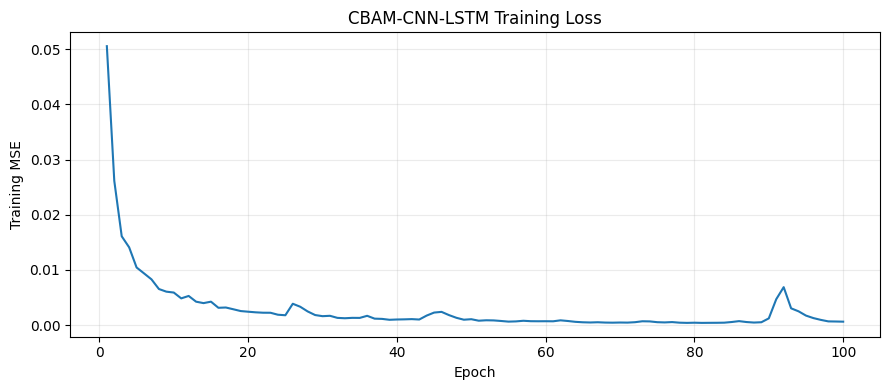

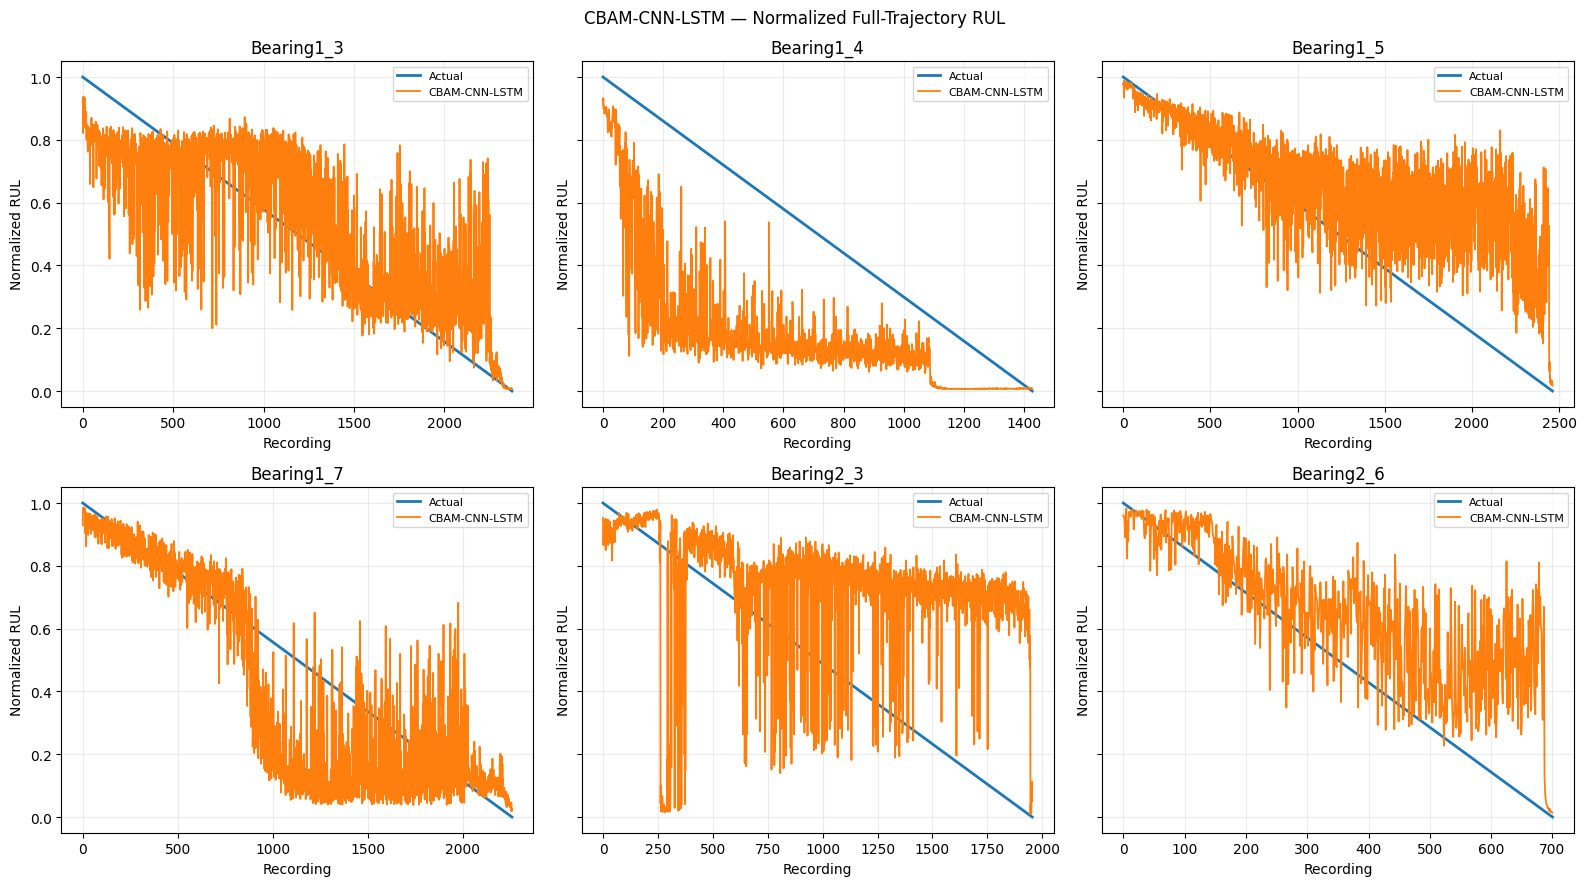

Saved metrics, predictions and plots to: /content/bearing_rul_cbam_only


In [ ]:
@torch.no_grad()
def predict_curve(model, x, batch_size=256):
    model.eval()
    out = []
    for start in range(0, len(x), batch_size):
        xb = torch.from_numpy(x[start:start+batch_size]).to(DEVICE)
        out.append(model(xb).clamp(0, 1).cpu().numpy())
    return np.concatenate(out)

model.eval()
per_rows, pred_rows = [], []
curves = {}

for name in TEST_BEARINGS:
    truth = test_labels[name].astype(np.float64)
    pred = predict_curve(model, X_test[name]).astype(np.float64)
    curves[name] = pred

    per_rows.append({
        "bearing": name,
        "n": len(truth),
        "MSE": mean_squared_error(truth, pred),
        "RMSE": np.sqrt(mean_squared_error(truth, pred)),
        "MAE": mean_absolute_error(truth, pred),
        "R2": r2_score(truth, pred)
    })

    for i, (a, p) in enumerate(zip(truth, pred)):
        pred_rows.append({
            "bearing": name,
            "snapshot": i,
            "actual_normalized_RUL": a,
            "predicted_normalized_RUL": p
        })

per_bearing_df = pd.DataFrame(per_rows)
predictions_df = pd.DataFrame(pred_rows)

pooled = {
    "MSE": mean_squared_error(predictions_df.actual_normalized_RUL, predictions_df.predicted_normalized_RUL),
    "RMSE": np.sqrt(mean_squared_error(predictions_df.actual_normalized_RUL, predictions_df.predicted_normalized_RUL)),
    "MAE": mean_absolute_error(predictions_df.actual_normalized_RUL, predictions_df.predicted_normalized_RUL),
    "R2": r2_score(predictions_df.actual_normalized_RUL, predictions_df.predicted_normalized_RUL)
}

macro = {
    "macro_MAE": per_bearing_df.MAE.mean(),
    "macro_RMSE": per_bearing_df.RMSE.mean(),
    "macro_R2": per_bearing_df.R2.mean()
}

print("PER-BEARING RESULTS")
display(per_bearing_df.round(5))
print("POOLED:", {k: round(v, 5) for k, v in pooled.items()})
print("MACRO:", {k: round(v, 5) for k, v in macro.items()})

paper_ref = pd.DataFrame([
    ["Bearing1_3", 0.037], ["Bearing1_4", 0.060],
    ["Bearing1_5", 0.091], ["Bearing1_7", 0.078],
    ["Bearing2_3", 0.112], ["Bearing2_6", 0.069]
], columns=["bearing", "published_MAE"])
ref_compare = per_bearing_df[["bearing", "MAE", "R2"]].merge(
    paper_ref, on="bearing", how="left"
)
print("PAPER REFERENCE COMPARISON (normalized MAE)")
display(ref_compare.round(5))
ref_compare.to_csv(OUT / "cbam_paper_reference_comparison.csv", index=False)

per_bearing_df.to_csv(OUT / "cbam_per_bearing_metrics.csv", index=False)
predictions_df.to_csv(OUT / "cbam_predictions.csv", index=False)

fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(history_df.epoch, history_df.train_MSE)
ax.set_xlabel("Epoch")
ax.set_ylabel("Training MSE")
ax.set_title("CBAM-CNN-LSTM Training Loss")
ax.grid(alpha=0.25)
fig.tight_layout()
fig.savefig(OUT / "cbam_training_loss.png", dpi=250)
plt.show()

fig, axes = plt.subplots(2, 3, figsize=(16, 9), sharey=True)
for ax, name in zip(axes.flat, TEST_BEARINGS):
    y = test_labels[name]
    ax.plot(y, label="Actual", linewidth=2)
    ax.plot(curves[name], label="CBAM-CNN-LSTM", linewidth=1.3)
    ax.set_title(name)
    ax.set_xlabel("Recording")
    ax.set_ylabel("Normalized RUL")
    ax.set_ylim(-0.05, 1.05)
    ax.grid(alpha=0.25)
    ax.legend(fontsize=8)
fig.suptitle("CBAM-CNN-LSTM — Normalized Full-Trajectory RUL")
fig.tight_layout()
fig.savefig(OUT / "cbam_normalized_rul_curves.png", dpi=250)
plt.show()

print("Saved metrics, predictions and plots to:", OUT)

,Method,Pooled MAE,Pooled RMSE,Pooled R2,Macro MAE
0,Raw CBAM,0.20170,0.27104,0.11940,0.20892
1,Median Filter,0.19607,0.26360,0.16709,0.20394
2,Isotonic,0.17696,0.24123,0.30242,0.18598
3,Median + Isotonic,0.18443,0.25056,0.24743,0.19343


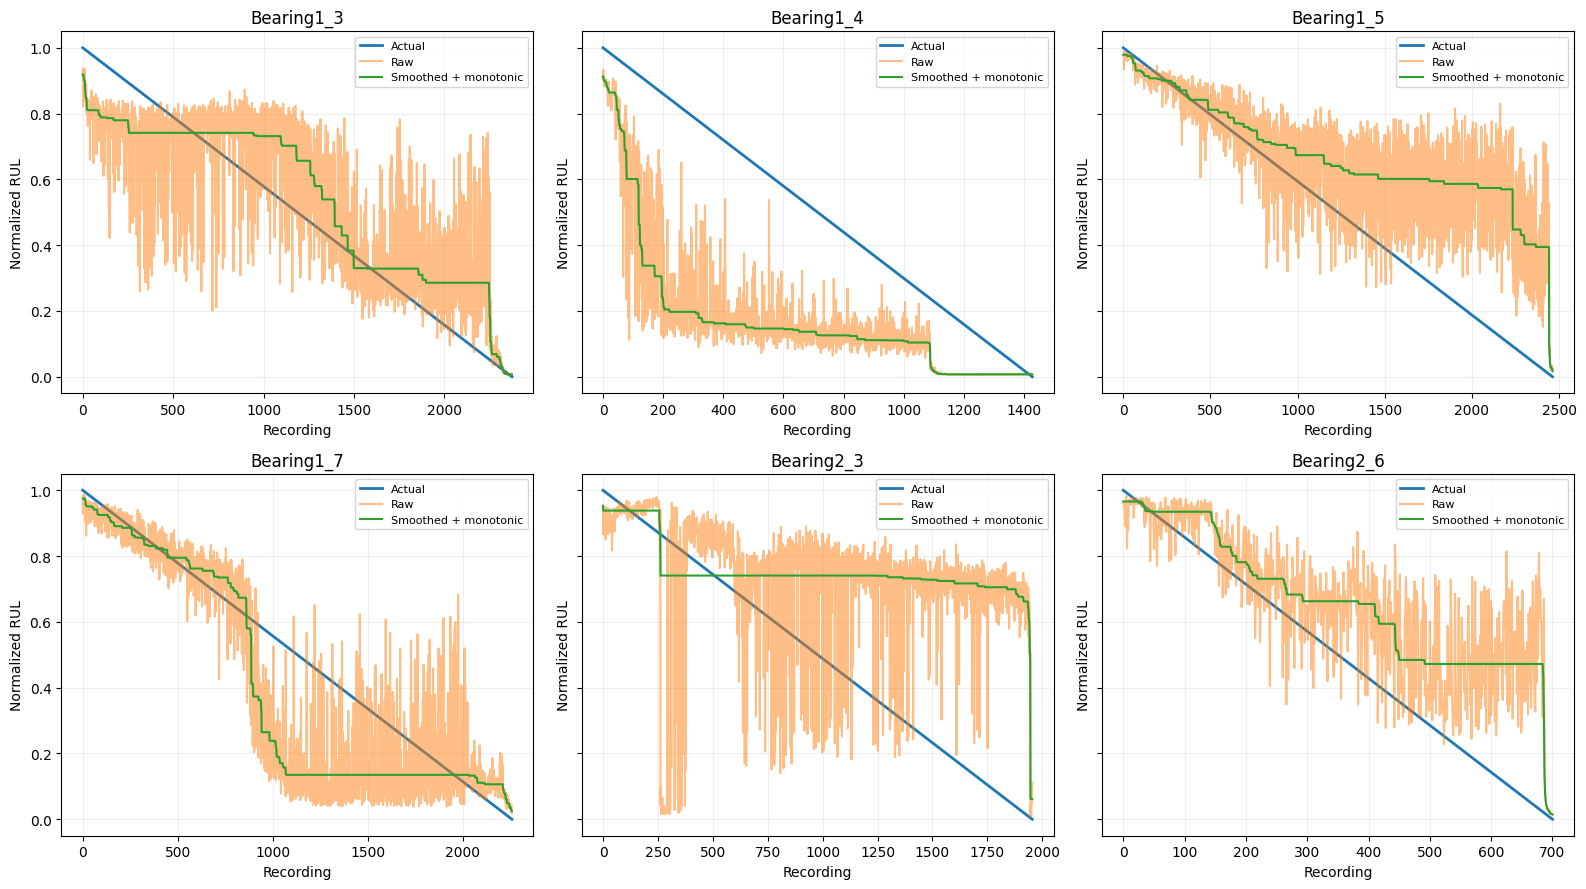

In [ ]:
from scipy.ndimage import median_filter
from sklearn.isotonic import IsotonicRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

variants = {
    "Raw CBAM": {},
    "Median Filter": {},
    "Isotonic": {},
    "Median + Isotonic": {}
}

for name in TEST_BEARINGS:
    raw = np.clip(curves[name].astype(float), 0, 1)
    y = test_labels[name].astype(float)

    med = median_filter(raw, size=11, mode="nearest")

    x = np.arange(len(raw))

    iso = IsotonicRegression(
        increasing=False, y_min=0, y_max=1
    )

    mono = iso.fit_transform(x, raw)
    med_mono = iso.fit_transform(x, med)

    variants["Raw CBAM"][name] = raw
    variants["Median Filter"][name] = med
    variants["Isotonic"][name] = mono
    variants["Median + Isotonic"][name] = med_mono


rows = []

for method, predictions in variants.items():

    all_actual, all_pred = [], []
    bearing_maes = []

    for name in TEST_BEARINGS:
        y = test_labels[name]
        p = predictions[name]

        mae = mean_absolute_error(y, p)
        bearing_maes.append(mae)

        all_actual.extend(y)
        all_pred.extend(p)

    rows.append({
        "Method": method,
        "Pooled MAE": mean_absolute_error(all_actual, all_pred),
        "Pooled RMSE": np.sqrt(mean_squared_error(all_actual, all_pred)),
        "Pooled R2": r2_score(all_actual, all_pred),
        "Macro MAE": np.mean(bearing_maes)
    })

smooth_results = pd.DataFrame(rows)

display(smooth_results.round(5))

fig, axes = plt.subplots(2, 3, figsize=(16, 9), sharey=True)

for ax, name in zip(axes.flat, TEST_BEARINGS):
    y = test_labels[name]

    ax.plot(y, label="Actual", linewidth=2)
    ax.plot(variants["Raw CBAM"][name], alpha=0.5, label="Raw")
    ax.plot(
        variants["Median + Isotonic"][name],
        label="Smoothed + monotonic",
        linewidth=1.5
    )

    ax.set_title(name)
    ax.set_xlabel("Recording")
    ax.set_ylabel("Normalized RUL")
    ax.legend(fontsize=8)
    ax.grid(alpha=0.2)

plt.tight_layout()
plt.show()

smooth_results.to_csv(
    OUT / "cbam_postprocessing_comparison.csv", index=False
)

Epoch 01 | loss=0.06829 | val MAE=0.23204 | best
Epoch 02 | loss=0.02979 | val MAE=0.17515 | best
Epoch 03 | loss=0.01604 | val MAE=0.17338 | best
Epoch 04 | loss=0.01398 | val MAE=0.20655 | wait 1/7
Epoch 05 | loss=0.01229 | val MAE=0.18492 | wait 2/7
Epoch 06 | loss=0.01028 | val MAE=0.19380 | wait 3/7
Epoch 07 | loss=0.00947 | val MAE=0.23343 | wait 4/7
Epoch 08 | loss=0.00888 | val MAE=0.21481 | wait 5/7
Epoch 09 | loss=0.00687 | val MAE=0.19259 | wait 6/7
Epoch 10 | loss=0.00768 | val MAE=0.31031 | wait 7/7

Best epoch: 3
Best validation macro MAE: 0.17338


,epoch,train_MSE,val_macro_MAE
0,1,0.068286,0.232043
1,2,0.029790,0.175148
2,3,0.016038,0.173375
3,4,0.013980,0.206552
4,5,0.012294,0.184924
5,6,0.010282,0.193801
6,7,0.009466,0.233432
7,8,0.008882,0.214814
8,9,0.006870,0.192594
9,10,0.007678,0.310305


Final training 1/3 | loss=0.06811
Final training 2/3 | loss=0.03967
Final training 3/3 | loss=0.02177

PER-BEARING RESULTS


,bearing,n,MAE,RMSE,R2
0,Bearing1_3,2346,0.28779,0.33063,-0.34330
1,Bearing1_4,1399,0.20145,0.22724,0.35528
2,Bearing1_5,2434,0.24670,0.28132,0.02830
3,Bearing1_7,2230,0.22099,0.25192,0.21918
4,Bearing2_3,1926,0.23149,0.29844,-0.10013
5,Bearing2_6,672,0.12431,0.14013,0.74432



POOLED RESULTS
MAE: 0.23437
RMSE: 0.2775
R2: 0.0478

MACRO RESULTS
MAE: 0.21879
RMSE: 0.25495
R2: 0.15061

OLD CBAM vs TEMPORAL CBAM
Old MAE: 0.2038
Temporal MAE: 0.23437
Old RMSE: 0.27295
Temporal RMSE: 0.2775
Old R2: 0.07873
Temporal R2: 0.0478


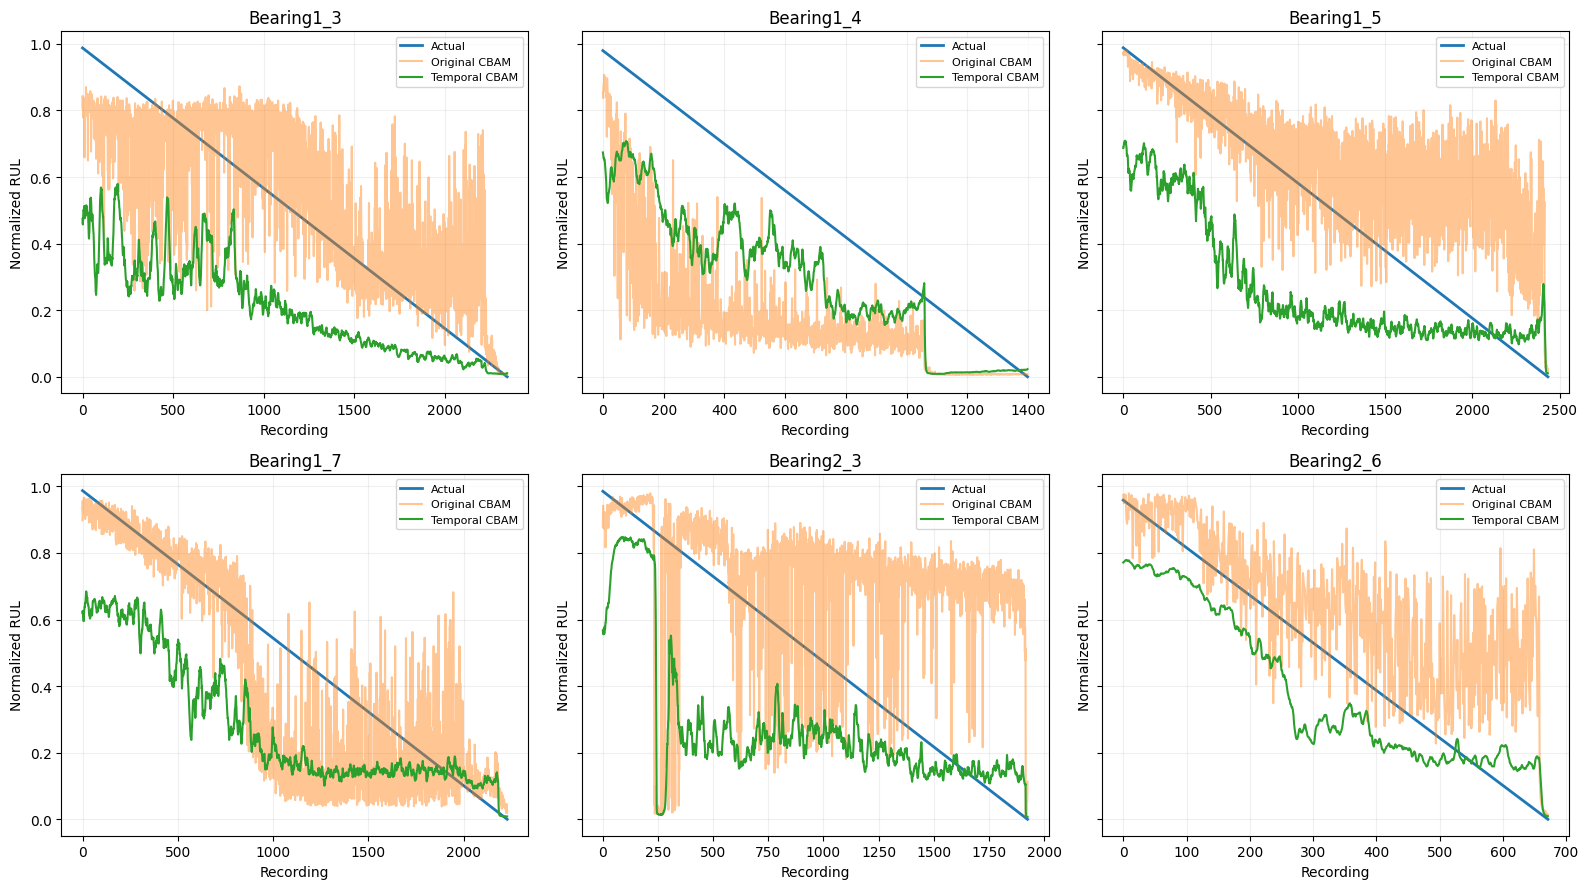

Saved temporal CBAM results to: /content/bearing_rul_cbam_only


In [ ]:
from torch.utils.data import Dataset, DataLoader, WeightedRandomSampler
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import copy, gc

W = 30
STRIDE = 4
BATCH = 12
EPOCHS = 40
PATIENCE = 7

VAL_BEARINGS = ["Bearing1_2", "Bearing3_1"]
FIT_BEARINGS = [b for b in TRAIN_BEARINGS if b not in VAL_BEARINGS]


class TemporalCBAM(Dataset):
    def __init__(self, xs, ys, names, stride=1):
        self.xs = {n: torch.tensor(xs[n], dtype=torch.float32) for n in names}
        self.ys = {n: torch.tensor(ys[n], dtype=torch.float32) for n in names}
        self.items = []

        counts = {}
        for n in names:
            ends = list(range(W - 1, len(xs[n]), stride))
            counts[n] = len(ends)
            self.items.extend((n, e) for e in ends)

        self.weights = [
            1.0 / counts[n] for n, _ in self.items
        ]

    def __len__(self):
        return len(self.items)

    def __getitem__(self, i):
        n, e = self.items[i]
        return self.xs[n][e-W+1:e+1], self.ys[n][e]


class CBAM1D(nn.Module):
    def __init__(self, channels=64, reduction=16, kernel=7):
        super().__init__()
        hidden = max(channels // reduction, 1)

        self.mlp = nn.Sequential(
            nn.Linear(channels, hidden),
            nn.ReLU(inplace=True),
            nn.Linear(hidden, channels)
        )

        self.spatial = nn.Conv1d(
            2, 1, kernel, padding=kernel // 2, bias=False
        )

    def forward(self, x):
        avg = x.mean(-1)
        mx = x.max(-1).values

        cw = torch.sigmoid(
            self.mlp(avg) + self.mlp(mx)
        ).unsqueeze(-1)

        x = x * cw

        s = torch.cat([
            x.mean(1, keepdim=True),
            x.max(1, keepdim=True).values
        ], dim=1)

        return x * torch.sigmoid(self.spatial(s))


class TemporalCBAMCNNLSTM(nn.Module):
    def __init__(self):
        super().__init__()

        self.conv1 = nn.Conv1d(1, 16, 32, stride=2)
        self.bn1 = nn.BatchNorm1d(16)

        self.conv2 = nn.Conv1d(16, 32, 10)
        self.bn2 = nn.BatchNorm1d(32)

        self.conv3 = nn.Conv1d(32, 64, 10)
        self.bn3 = nn.BatchNorm1d(64)

        self.pool = nn.MaxPool1d(2, 2)
        self.cbam = CBAM1D(64)

        self.freq_pool = nn.AdaptiveAvgPool1d(1)

        self.lstm = nn.LSTM(
            64, 128, num_layers=2,
            batch_first=True, dropout=0.2
        )

        self.fc = nn.Linear(128, 1)

    def forward(self, x):
        b, t, f = x.shape
        x = x.reshape(b * t, 1, f)

        x = self.pool(F.relu(self.bn1(self.conv1(x))))
        x = self.pool(F.relu(self.bn2(self.conv2(x))))
        x = self.cbam(F.relu(self.bn3(self.conv3(x))))

        x = self.freq_pool(x).squeeze(-1)
        x = x.reshape(b, t, 64)

        x, _ = self.lstm(x)

        return torch.sigmoid(
            self.fc(x[:, -1])
        ).squeeze(-1)


def prepare_scaled(names, scaler):
    return {
        n: np.nan_to_num(
            scaler.transform(train_spectra[n]).astype(np.float32)
        )
        for n in names
    }


def evaluate_temporal(model, xs, names):
    model.eval()
    results = {}

    with torch.no_grad():
        for n in names:
            ds = TemporalCBAM(
                xs, train_labels, [n], stride=1
            )
            dl = DataLoader(ds, batch_size=64, shuffle=False)

            pp, yy = [], []

            for xb, yb in dl:
                xb = xb.to(DEVICE)
                pp.extend(model(xb).cpu().numpy())
                yy.extend(yb.numpy())

            pp = np.asarray(pp)
            yy = np.asarray(yy)

            results[n] = {
                "pred": pp,
                "actual": yy,
                "MAE": mean_absolute_error(yy, pp),
                "RMSE": np.sqrt(mean_squared_error(yy, pp)),
                "R2": r2_score(yy, pp)
            }

    return results


def train_epoch(model, loader, optimizer):
    model.train()
    losses = []

    for xb, yb in loader:
        xb = xb.to(DEVICE)
        yb = yb.to(DEVICE)

        optimizer.zero_grad(set_to_none=True)

        pred = model(xb)
        loss = F.mse_loss(pred, yb)

        loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
        optimizer.step()

        losses.append(loss.item())

    return np.mean(losses)


# Validation on two complete held-out bearings
scaler_val = StandardScaler()
scaler_val.fit(np.concatenate([train_spectra[n] for n in FIT_BEARINGS]))

xs_val = prepare_scaled(TRAIN_BEARINGS, scaler_val)

train_ds = TemporalCBAM(
    xs_val, train_labels, FIT_BEARINGS, stride=STRIDE
)

sampler = WeightedRandomSampler(
    train_ds.weights, len(train_ds), replacement=True
)

train_dl = DataLoader(
    train_ds, batch_size=BATCH, sampler=sampler, num_workers=0
)

model = TemporalCBAMCNNLSTM().to(DEVICE)
optimizer = torch.optim.Adam(model.parameters(), lr=LR)

best_mae = float("inf")
best_state = None
best_epoch = 1
wait = 0
history = []

for epoch in range(1, EPOCHS + 1):

    loss = train_epoch(model, train_dl, optimizer)

    val_results = evaluate_temporal(
        model, xs_val, VAL_BEARINGS
    )

    val_mae = np.mean([
        val_results[n]["MAE"] for n in VAL_BEARINGS
    ])

    history.append({
        "epoch": epoch,
        "train_MSE": loss,
        "val_macro_MAE": val_mae
    })

    if val_mae < best_mae:
        best_mae = val_mae
        best_epoch = epoch
        best_state = {
            k: v.detach().cpu().clone()
            for k, v in model.state_dict().items()
        }
        wait = 0
        status = "best"
    else:
        wait += 1
        status = f"wait {wait}/{PATIENCE}"

    print(
        f"Epoch {epoch:02d} | loss={loss:.5f} | "
        f"val MAE={val_mae:.5f} | {status}"
    )

    if wait >= PATIENCE:
        break

model.load_state_dict(best_state)

print("\nBest epoch:", best_epoch)
print("Best validation macro MAE:", round(best_mae, 5))

display(pd.DataFrame(history))


# Retrain using all six learning bearings
del model, optimizer, train_dl, train_ds
gc.collect()

if DEVICE.type == "cuda":
    torch.cuda.empty_cache()

scaler_temporal = StandardScaler()
scaler_temporal.fit(
    np.concatenate([train_spectra[n] for n in TRAIN_BEARINGS])
)

xs_train = prepare_scaled(TRAIN_BEARINGS, scaler_temporal)

final_ds = TemporalCBAM(
    xs_train, train_labels, TRAIN_BEARINGS, stride=STRIDE
)

final_sampler = WeightedRandomSampler(
    final_ds.weights, len(final_ds), replacement=True
)

final_dl = DataLoader(
    final_ds, batch_size=BATCH,
    sampler=final_sampler, num_workers=0
)

temporal_model = TemporalCBAMCNNLSTM().to(DEVICE)
optimizer = torch.optim.Adam(temporal_model.parameters(), lr=LR)

for epoch in range(1, best_epoch + 1):
    loss = train_epoch(temporal_model, final_dl, optimizer)
    print(f"Final training {epoch}/{best_epoch} | loss={loss:.5f}")


# Predict complete test trajectories
def predict_temporal_curve(model, x):
    model.eval()
    out = []

    with torch.no_grad():
        for start in range(W - 1, len(x), 32):
            ends = range(start, min(start + 32, len(x)))

            batch = np.stack([
                x[e-W+1:e+1] for e in ends
            ]).astype(np.float32)

            p = model(
                torch.from_numpy(batch).to(DEVICE)
            )

            out.extend(p.cpu().numpy())

    return np.asarray(out)


temporal_curves = {}
rows = []

for n in TEST_BEARINGS:
    xt = np.nan_to_num(
        scaler_temporal.transform(test_spectra[n]).astype(np.float32)
    )

    pred = predict_temporal_curve(temporal_model, xt)
    actual = test_labels[n][W-1:]

    temporal_curves[n] = pred

    rows.append({
        "bearing": n,
        "n": len(actual),
        "MAE": mean_absolute_error(actual, pred),
        "RMSE": np.sqrt(mean_squared_error(actual, pred)),
        "R2": r2_score(actual, pred)
    })

temporal_metrics = pd.DataFrame(rows)

all_actual = np.concatenate([
    test_labels[n][W-1:] for n in TEST_BEARINGS
])

all_pred = np.concatenate([
    temporal_curves[n] for n in TEST_BEARINGS
])

print("\nPER-BEARING RESULTS")
display(temporal_metrics.round(5))

print("\nPOOLED RESULTS")
print("MAE:", round(mean_absolute_error(all_actual, all_pred), 5))
print("RMSE:", round(np.sqrt(mean_squared_error(all_actual, all_pred)), 5))
print("R2:", round(r2_score(all_actual, all_pred), 5))

print("\nMACRO RESULTS")
print("MAE:", round(temporal_metrics.MAE.mean(), 5))
print("RMSE:", round(temporal_metrics.RMSE.mean(), 5))
print("R2:", round(temporal_metrics.R2.mean(), 5))


# Compare against the old CBAM on the same recording range
if "curves" in globals():
    old_actual = np.concatenate([
        test_labels[n][W-1:] for n in TEST_BEARINGS
    ])
    old_pred = np.concatenate([
        curves[n][W-1:] for n in TEST_BEARINGS
    ])

    print("\nOLD CBAM vs TEMPORAL CBAM")
    print("Old MAE:", round(mean_absolute_error(old_actual, old_pred), 5))
    print("Temporal MAE:", round(mean_absolute_error(all_actual, all_pred), 5))
    print("Old RMSE:", round(np.sqrt(mean_squared_error(old_actual, old_pred)), 5))
    print("Temporal RMSE:", round(np.sqrt(mean_squared_error(all_actual, all_pred)), 5))
    print("Old R2:", round(r2_score(old_actual, old_pred), 5))
    print("Temporal R2:", round(r2_score(all_actual, all_pred), 5))


fig, axes = plt.subplots(2, 3, figsize=(16, 9), sharey=True)

for ax, n in zip(axes.flat, TEST_BEARINGS):
    ax.plot(test_labels[n][W-1:], label="Actual", linewidth=2)
    ax.plot(curves[n][W-1:], alpha=0.45, label="Original CBAM")
    ax.plot(temporal_curves[n], label="Temporal CBAM")

    ax.set_title(n)
    ax.set_xlabel("Recording")
    ax.set_ylabel("Normalized RUL")
    ax.legend(fontsize=8)
    ax.grid(alpha=0.2)

plt.tight_layout()
plt.savefig(OUT / "temporal_cbam_comparison.png", dpi=300)
plt.show()


torch.save(temporal_model.state_dict(), OUT / "temporal_cbam.pt")
joblib.dump(scaler_temporal, OUT / "temporal_cbam_scaler.joblib")

temporal_metrics.to_csv(
    OUT / "temporal_cbam_metrics.csv", index=False
)

pd.DataFrame({
    "bearing": np.repeat(TEST_BEARINGS, [
        len(temporal_curves[n]) for n in TEST_BEARINGS
    ]),
    "prediction": np.concatenate([
        temporal_curves[n] for n in TEST_BEARINGS
    ])
}).to_csv(OUT / "temporal_cbam_predictions.csv", index=False)

print("Saved temporal CBAM results to:", OUT)

In [ ]:
from sklearn.isotonic import IsotonicRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np
import pandas as pd

results = []
final_curves = {}

for name in TEST_BEARINGS:

    y = test_labels[name][W-1:]

    raw = curves[name][W-1:]
    temporal = temporal_curves[name]

    iso = IsotonicRegression(
        increasing=False,
        y_min=0,
        y_max=1
    )

    corrected = iso.fit_transform(
        np.arange(len(raw)), raw
    )

    final_curves[name] = {
        "actual": y,
        "original": raw,
        "temporal": temporal,
        "isotonic": corrected
    }

    for method, pred in [
        ("Original CBAM", raw),
        ("Temporal CBAM", temporal),
        ("Original CBAM + Isotonic", corrected)
    ]:
        results.append({
            "bearing": name,
            "method": method,
            "MAE": mean_absolute_error(y, pred),
            "RMSE": np.sqrt(mean_squared_error(y, pred)),
            "R2": r2_score(y, pred)
        })

detail_df = pd.DataFrame(results)

summary = []

for method, g in detail_df.groupby("method"):
    y_all = np.concatenate([
        final_curves[n]["actual"] for n in TEST_BEARINGS
    ])

    p_all = np.concatenate([
        final_curves[n][
            "original" if method == "Original CBAM"
            else "temporal" if method == "Temporal CBAM"
            else "isotonic"
        ] for n in TEST_BEARINGS
    ])

    summary.append({
        "Model": method,
        "Pooled MAE": mean_absolute_error(y_all, p_all),
        "Pooled RMSE": np.sqrt(mean_squared_error(y_all, p_all)),
        "Pooled R2": r2_score(y_all, p_all),
        "Macro MAE": g.MAE.mean(),
        "Macro RMSE": g.RMSE.mean(),
        "Macro R2": g.R2.mean()
    })

summary_df = pd.DataFrame(summary).sort_values("Pooled MAE")

display(summary_df.round(5))
display(detail_df.round(5))

summary_df.to_csv(OUT / "final_cbam_comparison.csv", index=False)
detail_df.to_csv(OUT / "final_cbam_per_bearing.csv", index=False)

,Model,Pooled MAE,Pooled RMSE,Pooled R2,Macro MAE,Macro RMSE,Macro R2
1,Original CBAM + Isotonic,0.17878,0.24294,0.27022,0.18858,0.23544,0.20947
0,Original CBAM,0.20380,0.27295,0.07873,0.21178,0.26783,0.01837
2,Temporal CBAM,0.23437,0.27750,0.04780,0.21879,0.25495,0.15061


,bearing,method,MAE,RMSE,R2
0,Bearing1_3,Original CBAM,0.13469,0.17571,0.62062
1,Bearing1_3,Temporal CBAM,0.28779,0.33063,-0.34330
2,Bearing1_3,Original CBAM + Isotonic,0.10678,0.12425,0.81031
3,Bearing1_4,Original CBAM,0.32509,0.37761,-0.78026
4,Bearing1_4,Temporal CBAM,0.20145,0.22724,0.35528
5,Bearing1_4,Original CBAM + Isotonic,0.32507,0.37052,-0.71405
6,Bearing1_5,Original CBAM,0.18231,0.24486,0.26386
7,Bearing1_5,Temporal CBAM,0.24670,0.28132,0.02830
8,Bearing1_5,Original CBAM + Isotonic,0.16945,0.22586,0.37369
9,Bearing1_7,Original CBAM,0.13541,0.18707,0.56943


Epoch 01 | loss=0.04773 | val MAE=0.19836 | best
Epoch 05 | loss=0.01326 | val MAE=0.19727 | wait 1/10
Epoch 10 | loss=0.00487 | val MAE=0.21625 | wait 6/10

Best epoch: 4
Best validation macro MAE: 0.19141

PER-BEARING RESULTS


,bearing,method,MAE,RMSE,R2
0,Bearing1_2,Raw CBAM,0.23475,0.29493,-0.04143
1,Bearing1_2,CBAM + Isotonic,0.22557,0.27991,0.06194
2,Bearing3_1,Raw CBAM,0.14807,0.19498,0.54557
3,Bearing3_1,CBAM + Isotonic,0.13377,0.17132,0.64914



SUMMARY


,Model,Pooled MAE,Pooled RMSE,Pooled R2,Macro MAE,Macro RMSE,Macro R2
0,Raw CBAM,0.20254,0.26228,0.17690,0.19141,0.24496,0.25207
1,CBAM + Isotonic,0.19146,0.24524,0.28035,0.17967,0.22562,0.35554


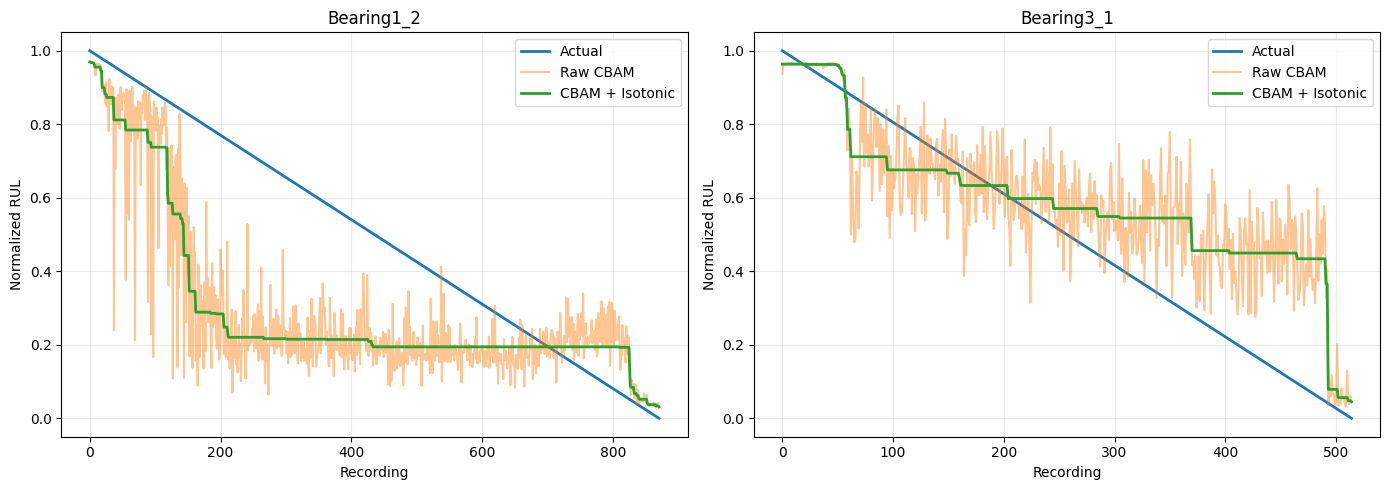

Saved validation results to: /content/bearing_rul_cbam_only


In [ ]:
from sklearn.isotonic import IsotonicRegression

VAL_BEARINGS = ["Bearing1_2", "Bearing3_1"]
FIT_BEARINGS = [b for b in TRAIN_BEARINGS if b not in VAL_BEARINGS]

EPOCHS_CV = 60
PATIENCE = 10

scaler_cv = StandardScaler()
scaler_cv.fit(np.concatenate([train_spectra[n] for n in FIT_BEARINGS]))

X_fit = np.nan_to_num(np.concatenate([
    scaler_cv.transform(train_spectra[n]).astype(np.float32)
    for n in FIT_BEARINGS
]))

y_fit = np.concatenate([train_labels[n] for n in FIT_BEARINGS])

train_dl = DataLoader(
    TensorDataset(torch.from_numpy(X_fit), torch.from_numpy(y_fit)),
    batch_size=128, shuffle=True, num_workers=0
)

X_val = {
    n: np.nan_to_num(
        scaler_cv.transform(train_spectra[n]).astype(np.float32)
    )
    for n in VAL_BEARINGS
}


@torch.no_grad()
def predict_cbam(m, x):
    m.eval()
    out = []

    for i in range(0, len(x), 256):
        xb = torch.tensor(x[i:i+256], dtype=torch.float32, device=DEVICE)
        out.append(m(xb).clamp(0, 1).cpu().numpy())

    return np.concatenate(out)


torch.manual_seed(SEED + 50)
model_cv = CBAMCNNLSTM().to(DEVICE)
opt = torch.optim.Adam(model_cv.parameters(), lr=LR)

best_mae = float("inf")
best_state = None
wait = 0
history_cv = []

for epoch in range(1, EPOCHS_CV + 1):
    model_cv.train()
    losses = []

    for xb, yb in train_dl:
        xb = xb.to(DEVICE)
        yb = yb.to(DEVICE)

        opt.zero_grad(set_to_none=True)
        pred = model_cv(xb)
        loss = F.mse_loss(pred, yb)
        loss.backward()
        opt.step()

        losses.append(loss.item())

    val_preds = {
        n: predict_cbam(model_cv, X_val[n])
        for n in VAL_BEARINGS
    }

    val_mae = np.mean([
        mean_absolute_error(train_labels[n], val_preds[n])
        for n in VAL_BEARINGS
    ])

    history_cv.append({
        "epoch": epoch,
        "train_MSE": np.mean(losses),
        "val_macro_MAE": val_mae
    })

    if val_mae < best_mae:
        best_mae = val_mae
        best_state = {
            k: v.detach().cpu().clone()
            for k, v in model_cv.state_dict().items()
        }
        best_epoch = epoch
        wait = 0
        status = "best"
    else:
        wait += 1
        status = f"wait {wait}/{PATIENCE}"

    if epoch == 1 or epoch % 5 == 0:
        print(
            f"Epoch {epoch:02d} | "
            f"loss={np.mean(losses):.5f} | "
            f"val MAE={val_mae:.5f} | {status}"
        )

    if wait >= PATIENCE:
        break

model_cv.load_state_dict(best_state)
print("\nBest epoch:", best_epoch)
print("Best validation macro MAE:", round(best_mae, 5))


# Raw vs isotonic predictions
rows = []
cv_curves = {}

for n in VAL_BEARINGS:
    y = train_labels[n].astype(float)
    raw = predict_cbam(model_cv, X_val[n])

    iso = IsotonicRegression(
        increasing=False,
        y_min=0,
        y_max=1
    )

    corrected = iso.fit_transform(
        np.arange(len(raw)), raw
    )

    cv_curves[n] = {
        "actual": y,
        "raw": raw,
        "isotonic": corrected
    }

    for method, p in [
        ("Raw CBAM", raw),
        ("CBAM + Isotonic", corrected)
    ]:
        rows.append({
            "bearing": n,
            "method": method,
            "MAE": mean_absolute_error(y, p),
            "RMSE": np.sqrt(mean_squared_error(y, p)),
            "R2": r2_score(y, p)
        })

detail_cv = pd.DataFrame(rows)

summary_cv = []

for method in detail_cv.method.unique():
    g = detail_cv[detail_cv.method == method]

    actual = np.concatenate([
        cv_curves[n]["actual"] for n in VAL_BEARINGS
    ])

    pred = np.concatenate([
        cv_curves[n][
            "raw" if method == "Raw CBAM" else "isotonic"
        ] for n in VAL_BEARINGS
    ])

    summary_cv.append({
        "Model": method,
        "Pooled MAE": mean_absolute_error(actual, pred),
        "Pooled RMSE": np.sqrt(mean_squared_error(actual, pred)),
        "Pooled R2": r2_score(actual, pred),
        "Macro MAE": g.MAE.mean(),
        "Macro RMSE": g.RMSE.mean(),
        "Macro R2": g.R2.mean()
    })

summary_cv = pd.DataFrame(summary_cv)

print("\nPER-BEARING RESULTS")
display(detail_cv.round(5))

print("\nSUMMARY")
display(summary_cv.round(5))


fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for ax, n in zip(axes, VAL_BEARINGS):
    ax.plot(cv_curves[n]["actual"], label="Actual", linewidth=2)
    ax.plot(cv_curves[n]["raw"], label="Raw CBAM", alpha=0.45)
    ax.plot(
        cv_curves[n]["isotonic"],
        label="CBAM + Isotonic",
        linewidth=2
    )
    ax.set_title(n)
    ax.set_xlabel("Recording")
    ax.set_ylabel("Normalized RUL")
    ax.legend()
    ax.grid(alpha=0.25)

plt.tight_layout()
plt.savefig(OUT / "heldout_cbam_isotonic.png", dpi=250)
plt.show()


summary_cv.to_csv(OUT / "heldout_cbam_summary.csv", index=False)
detail_cv.to_csv(OUT / "heldout_cbam_per_bearing.csv", index=False)
pd.DataFrame(history_cv).to_csv(
    OUT / "heldout_cbam_training_history.csv", index=False
)

torch.save({
    "model_state_dict": best_state,
    "best_epoch": best_epoch,
    "heldout_bearings": VAL_BEARINGS
}, OUT / "heldout_cbam_model.pt")

print("Saved validation results to:", OUT)

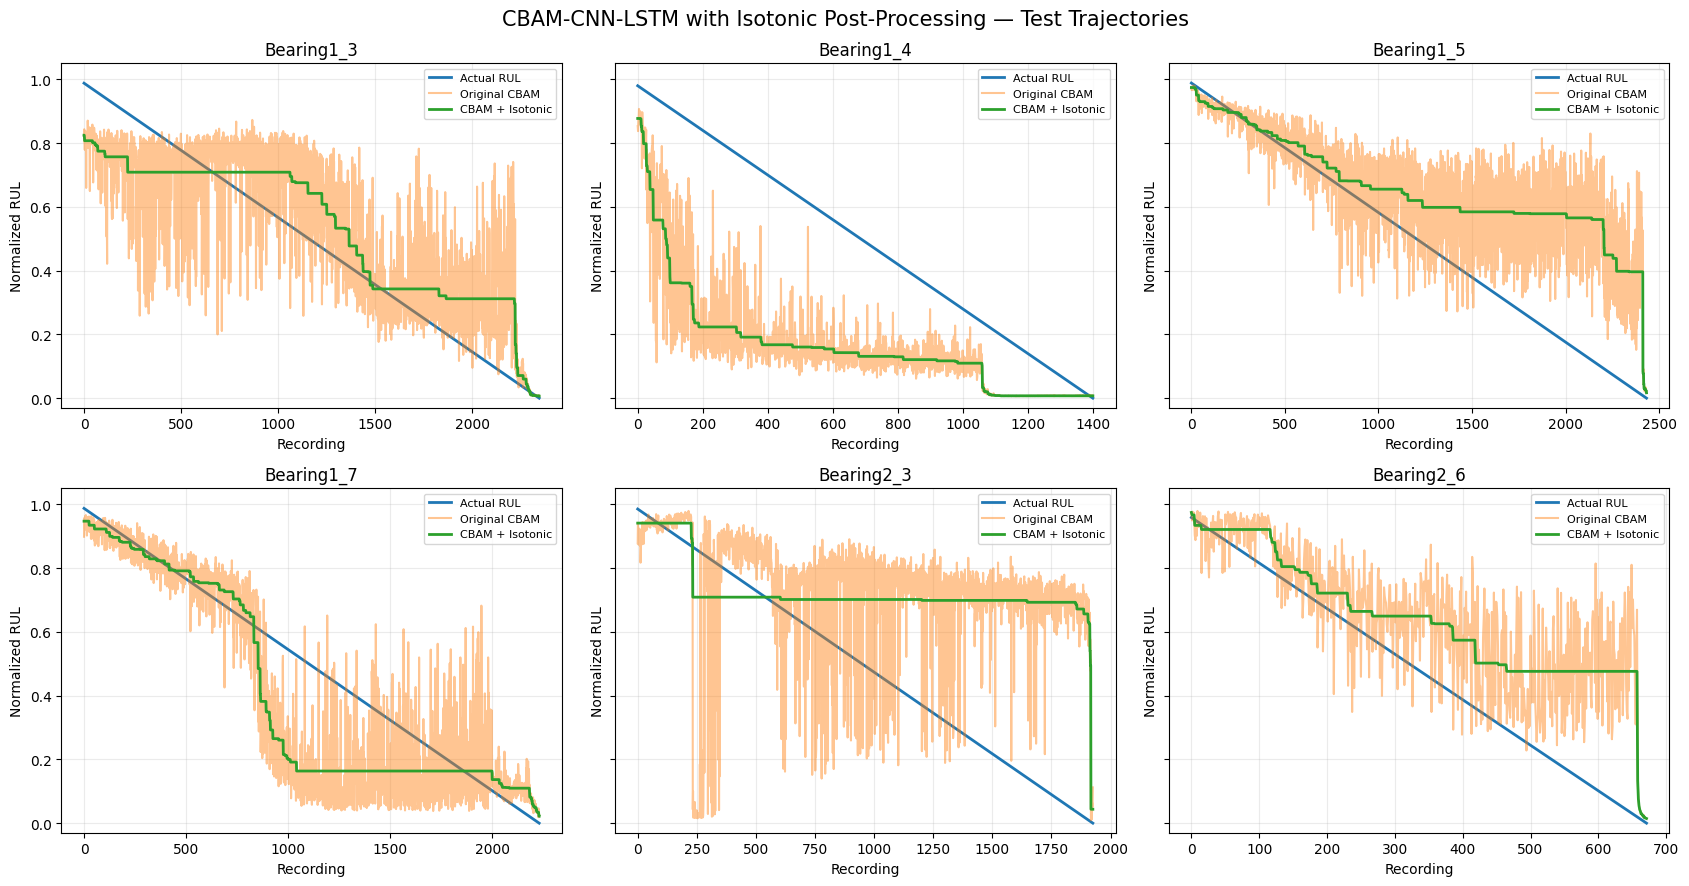

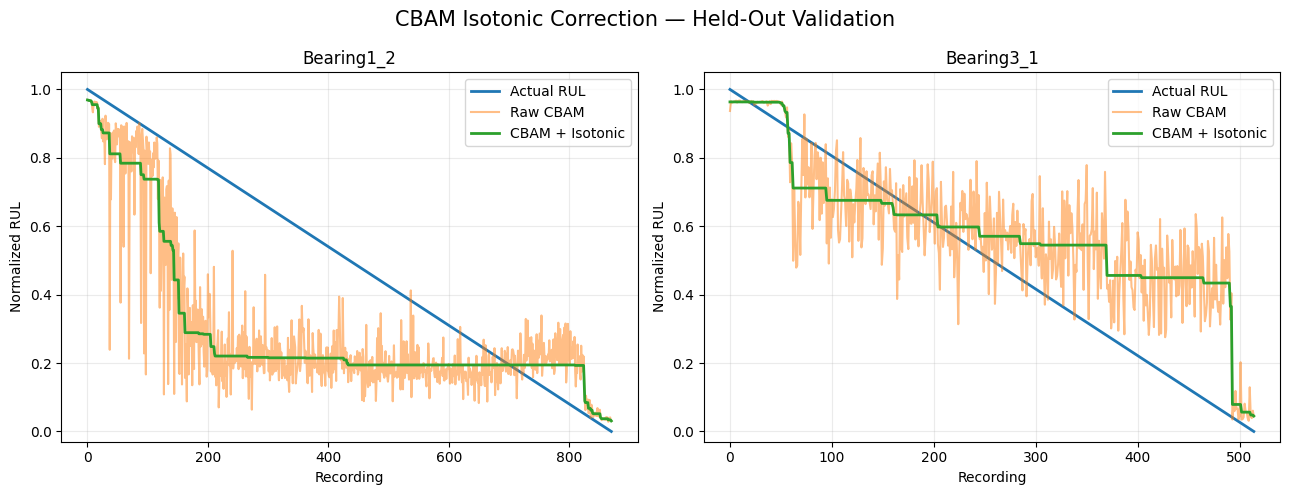

,Evaluation,Model,Pooled MAE,Pooled RMSE,Pooled R2,Macro MAE,Macro R2
0,Six test trajectories,CBAM + Isotonic,0.17878,0.24294,0.27022,0.18858,0.20947
1,Two held-out learning bearings,CBAM + Isotonic,0.19146,0.24524,0.28035,0.17967,0.35554


Final results saved to: /content/bearing_rul_cbam_only/final_results


In [ ]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

out = os.path.join(str(OUT), "final_results")
os.makedirs(out, exist_ok=True)

# Save metric tables
summary_df.to_csv(
    os.path.join(out, "test_model_comparison.csv"), index=False
)
detail_df.to_csv(
    os.path.join(out, "test_per_bearing_metrics.csv"), index=False
)
summary_cv.to_csv(
    os.path.join(out, "validation_model_comparison.csv"), index=False
)
detail_cv.to_csv(
    os.path.join(out, "validation_per_bearing_metrics.csv"), index=False
)

# Test trajectory plots
fig, axes = plt.subplots(2, 3, figsize=(17, 9), sharey=True)
axes = axes.flatten()

for ax, name in zip(axes, TEST_BEARINGS):
    d = final_curves[name]

    ax.plot(d["actual"], label="Actual RUL", linewidth=2)
    ax.plot(d["original"], label="Original CBAM", alpha=0.45)
    ax.plot(
        d["isotonic"],
        label="CBAM + Isotonic",
        linewidth=2
    )

    ax.set_title(name)
    ax.set_xlabel("Recording")
    ax.set_ylabel("Normalized RUL")
    ax.set_ylim(-0.03, 1.05)
    ax.grid(alpha=0.25)
    ax.legend(fontsize=8)

fig.suptitle(
    "CBAM-CNN-LSTM with Isotonic Post-Processing — Test Trajectories",
    fontsize=15
)
plt.tight_layout()
plt.savefig(
    os.path.join(out, "test_trajectory_comparison.png"),
    dpi=300, bbox_inches="tight"
)
plt.show()

# Held-out validation plots
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

for ax, name in zip(axes, VAL_BEARINGS):
    d = cv_curves[name]

    ax.plot(d["actual"], label="Actual RUL", linewidth=2)
    ax.plot(d["raw"], label="Raw CBAM", alpha=0.5)
    ax.plot(
        d["isotonic"],
        label="CBAM + Isotonic",
        linewidth=2
    )

    ax.set_title(name)
    ax.set_xlabel("Recording")
    ax.set_ylabel("Normalized RUL")
    ax.set_ylim(-0.03, 1.05)
    ax.grid(alpha=0.25)
    ax.legend()

fig.suptitle(
    "CBAM Isotonic Correction — Held-Out Validation",
    fontsize=15
)
plt.tight_layout()
plt.savefig(
    os.path.join(out, "validation_trajectory_comparison.png"),
    dpi=300, bbox_inches="tight"
)
plt.show()

# Compact final summary
test_best = summary_df[
    summary_df["Model"] == "Original CBAM + Isotonic"
].iloc[0]

val_best = summary_cv[
    summary_cv["Model"] == "CBAM + Isotonic"
].iloc[0]

final_summary = pd.DataFrame([
    {
        "Evaluation": "Six test trajectories",
        "Model": "CBAM + Isotonic",
        "Pooled MAE": test_best["Pooled MAE"],
        "Pooled RMSE": test_best["Pooled RMSE"],
        "Pooled R2": test_best["Pooled R2"],
        "Macro MAE": test_best["Macro MAE"],
        "Macro R2": test_best["Macro R2"]
    },
    {
        "Evaluation": "Two held-out learning bearings",
        "Model": "CBAM + Isotonic",
        "Pooled MAE": val_best["Pooled MAE"],
        "Pooled RMSE": val_best["Pooled RMSE"],
        "Pooled R2": val_best["Pooled R2"],
        "Macro MAE": val_best["Macro MAE"],
        "Macro R2": val_best["Macro R2"]
    }
])

display(final_summary.round(5))

final_summary.to_csv(
    os.path.join(out, "final_project_summary.csv"),
    index=False
)

print("Final results saved to:", out)

In [ ]:
from google.colab import drive
from pathlib import Path
import shutil
import os

drive.mount('/content/drive')

src = Path("/content/bearing_rul_cbam_only")
dst = Path("/content/drive/MyDrive/dnn_project") / src.name

if not src.exists():
    raise FileNotFoundError(f"Project folder not found: {src}")

shutil.copytree(src, dst, dirs_exist_ok=True)

files = [p for p in dst.rglob("*") if p.is_file()]
size = sum(p.stat().st_size for p in files) / (1024 ** 2)

print("Backup completed!")
print("Drive location:", dst)
print("Files copied:", len(files))
print(f"Total size: {size:.2f} MB")

Mounted at /content/drive
Backup completed!
Drive location: /content/drive/MyDrive/dnn_project/bearing_rul_cbam_only
Files copied: 28
Total size: 7.14 MB


In [7]:
!pip -q install PyWavelets

import pywt
from scipy.stats import skew
from tqdm.auto import tqdm

feature_names = (
    ["RS_time", "RS_fft_full"] +
    [f"RS_fft_{i}" for i in range(1, 5)] +
    [f"WPT_{i}" for i in range(1, 9)]
)

def corr_abs(a, b):
    a, b = np.ravel(a), np.ravel(b)

    if np.std(a) < 1e-10 or np.std(b) < 1e-10:
        return float(np.allclose(a, b))

    r = np.corrcoef(a, b)[0, 1]
    return float(abs(r)) if np.isfinite(r) else 0.0


def extract_features(x):
    x = np.asarray(x, dtype=np.float64)
    x = x - x.mean()

    rms = np.sqrt(np.mean(x**2))
    mean_abs = np.mean(np.abs(x))
    peak = np.max(np.abs(x))
    eps = 1e-10

    tf = np.array([
        np.mean(x),
        rms,
        np.min(x),
        np.sqrt(np.mean((x-x.mean())**2)),
        np.ptp(x),
        np.mean(np.abs(x-x.mean())**4) / (rms**4 + eps),
        peak / (rms + eps),
        skew(x, bias=False),
        peak / (mean_abs + eps),
        rms / (mean_abs + eps)
    ])

    spec = np.abs(np.fft.rfft(x))
    idx = np.array_split(np.arange(len(spec)), 4)

    wp = pywt.WaveletPacket(
        data=x, wavelet="haar", mode="symmetric", maxlevel=3
    )

    nodes = wp.get_level(3, order="freq")
    energy = np.array([
        np.sum(node.data**2) for node in nodes
    ])

    energy = energy / (energy.sum() + eps)

    return tf, spec, energy


def extract_bearing_features(folder):
    paths = get_files(folder)
    base_tf = base_spec = None
    bands = None
    rows = []

    for path in paths:
        x = read_signal(path)
        tf, spec, energy = extract_features(x)

        if base_tf is None:
            base_tf = tf.copy()
            base_spec = spec.copy()
            bands = np.array_split(np.arange(len(spec)), 4)

        rs_time = corr_abs(base_tf, tf)

        rs_freq = [corr_abs(base_spec, spec)]

        for ids in bands:
            rs_freq.append(
                corr_abs(base_spec[ids], spec[ids])
            )

        rows.append([rs_time] + rs_freq + energy.tolist())

    return np.nan_to_num(np.asarray(rows, dtype=np.float32))


feature_bank = {}

for name in TRAIN_BEARINGS:
    print("Extracting", name)
    feature_bank[name] = extract_bearing_features(
        LEARNING_DIR / name
    )

for name in TEST_BEARINGS:
    print("Extracting", name)
    feature_bank[name] = extract_bearing_features(
        FULL_TEST_DIR / name
    )

print("\nFeature dimensions:")
for name, x in feature_bank.items():
    print(name, x.shape)

np.savez_compressed(
    OUT / "similarity_wavelet_features.npz",
    **feature_bank
)

print("Saved feature extraction.")

Extracting Bearing1_1
Extracting Bearing1_2
Extracting Bearing2_1
Extracting Bearing2_2
Extracting Bearing3_1
Extracting Bearing3_2
Extracting Bearing1_3
Extracting Bearing1_4
Extracting Bearing1_5
Extracting Bearing1_7
Extracting Bearing2_3
Extracting Bearing2_6

Feature dimensions:
Bearing1_1 (2803, 14)
Bearing1_2 (871, 14)
Bearing2_1 (911, 14)
Bearing2_2 (797, 14)
Bearing3_1 (515, 14)
Bearing3_2 (1637, 14)
Bearing1_3 (2375, 14)
Bearing1_4 (1428, 14)
Bearing1_5 (2463, 14)
Bearing1_7 (2259, 14)
Bearing2_3 (1955, 14)
Bearing2_6 (701, 14)
Saved feature extraction.


Selected features:


,feature,Cori
8,WPT_3,0.491
1,RS_fft_full,0.434
9,WPT_4,0.431
10,WPT_5,0.403
13,WPT_8,0.391
11,WPT_6,0.368
2,RS_fft_1,0.365
7,WPT_2,0.351
0,RS_time,0.347
5,RS_fft_4,0.317


Epoch 001 | loss=0.05208 | val MAE=0.24185 | best
Epoch 005 | loss=0.02249 | val MAE=0.27657 | wait 4/12
Epoch 010 | loss=0.02234 | val MAE=0.28263 | wait 9/12

Best epoch: 1
Best validation macro MAE: 0.24185

VALIDATION RESULTS


,bearing,method,MAE,RMSE,R2
0,Bearing1_2,Raw CNN,0.19512,0.23705,0.31309
1,Bearing1_2,CNN + Isotonic,0.19512,0.23520,0.32381
2,Bearing3_1,Raw CNN,0.28858,0.32723,-0.32595
3,Bearing3_1,CNN + Isotonic,0.28638,0.32628,-0.31821


Selected features:


,feature,Cori
8,WPT_3,0.532
13,WPT_8,0.498
1,RS_fft_full,0.494
9,WPT_4,0.407
11,WPT_6,0.385
10,WPT_5,0.384
0,RS_time,0.377
7,WPT_2,0.369
2,RS_fft_1,0.345
4,RS_fft_3,0.335


Final training 1/1 | loss=0.05564

TEST PER-BEARING RESULTS


,bearing,method,MAE,RMSE,R2
0,Bearing1_3,Raw CNN,0.11673,0.14275,0.75380
1,Bearing1_3,CNN + Isotonic,0.11673,0.14229,0.75538
2,Bearing1_4,Raw CNN,0.19044,0.22000,0.41264
3,Bearing1_4,CNN + Isotonic,0.18151,0.20079,0.51072
4,Bearing1_5,Raw CNN,0.13950,0.15792,0.69878
5,Bearing1_5,CNN + Isotonic,0.13950,0.15783,0.69912
6,Bearing1_7,Raw CNN,0.10013,0.14345,0.75131
7,Bearing1_7,CNN + Isotonic,0.09682,0.13007,0.79554
8,Bearing2_3,Raw CNN,0.27050,0.31462,-0.19762
9,Bearing2_3,CNN + Isotonic,0.26234,0.30969,-0.16037



FINAL SUMMARY


,Model,Pooled MAE,Pooled RMSE,Pooled R2,Macro MAE,Macro RMSE,Macro R2
0,Raw CNN,0.15871,0.20027,0.51455,0.16644,0.19740,0.48328
1,CNN + Isotonic,0.15544,0.19432,0.54297,0.16295,0.19102,0.51367


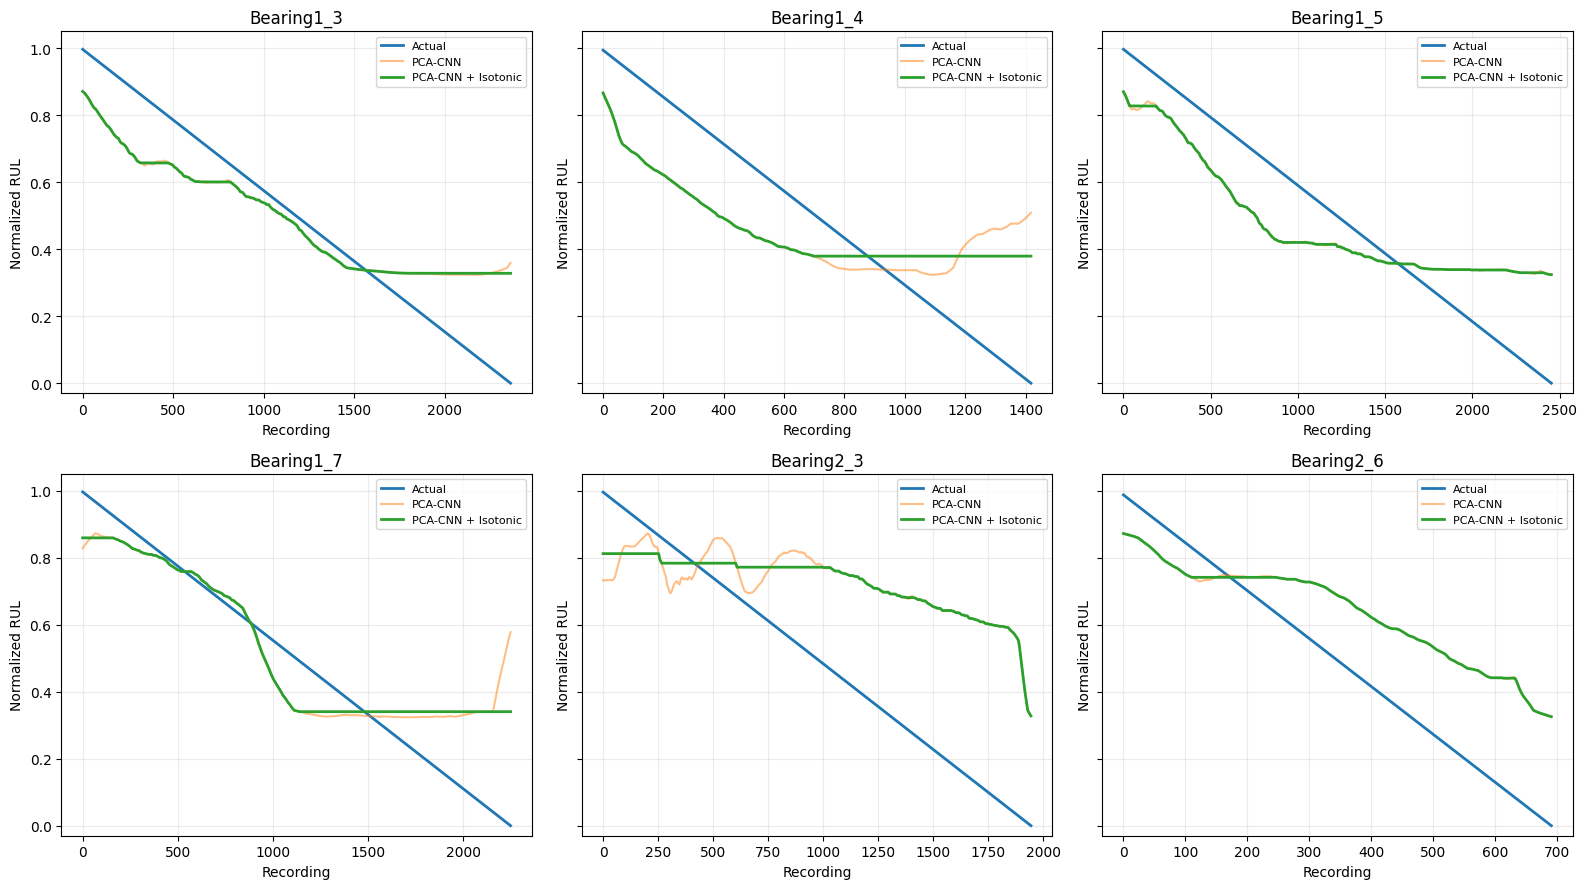

Saved experiment to: /content/bearing_rul_cbam_only


In [9]:
from scipy.ndimage import uniform_filter1d
from sklearn.decomposition import PCA
from torch.utils.data import TensorDataset, DataLoader
from sklearn.isotonic import IsotonicRegression

import copy
import gc

VAL_BEARINGS = ["Bearing1_2", "Bearing3_1"]
FIT_BEARINGS = [
    n for n in TRAIN_BEARINGS if n not in VAL_BEARINGS
]

WIN = 10
MAX_EPOCHS = 100
PATIENCE = 12
BS = 128

all_names = TRAIN_BEARINGS + TEST_BEARINGS

smooth_bank = {
    n: uniform_filter1d(
        x, size=100, axis=0, mode="nearest"
    )
    for n, x in feature_bank.items()
}


def cori_score(x):
    t = np.arange(len(x))
    r = np.corrcoef(t, x)[0, 1]

    trend = abs(r) if np.isfinite(r) else 0
    d = np.diff(x)

    mono = abs(
        (np.sum(d > 0) - np.sum(d < 0)) / max(len(d), 1)
    )

    return (trend + mono) / 2


def prepare_hi(select_names, fit_names):
    scores = np.mean([
        np.array([
            cori_score(smooth_bank[n][:, j])
            for j in range(len(feature_names))
        ])
        for n in select_names
    ], axis=0)

    score_df = pd.DataFrame({
        "feature": feature_names,
        "Cori": scores
    }).sort_values("Cori", ascending=False)

    selected = np.where(scores >= 0.5)[0]

    if len(selected) < 4:
        selected = np.argsort(scores)[-6:]

    selected = sorted(selected.tolist())

    print("Selected features:")
    display(score_df.round(3))

    def scale(x):
        x = x[:, selected]
        lo = x.min(axis=0)
        hi = x.max(axis=0)
        return np.clip(
            (x - lo) / (hi - lo + 1e-8), 0, 1
        ).astype(np.float32)

    scaled = {
        n: scale(smooth_bank[n]) for n in all_names
    }

    pca = PCA(n_components=1)
    pca.fit(np.concatenate([scaled[n] for n in fit_names]))

    trends = []

    for n in fit_names:
        pc = pca.transform(scaled[n]).ravel()
        r = np.corrcoef(np.arange(len(pc)), pc)[0, 1]
        trends.append(r if np.isfinite(r) else 0)

    direction = -1 if np.mean(trends) > 0 else 1

    hi_bank = {}

    for n in all_names:
        pc = pca.transform(scaled[n]).ravel() * direction
        lo, hi = pc.min(), pc.max()

        hi_bank[n] = np.clip(
            (pc - lo) / (hi - lo + 1e-8), 0, 1
        ).astype(np.float32)

    return hi_bank, pca, selected, score_df


def make_windows(names, hi_bank, labels):
    X, y = [], []

    for n in names:
        h = hi_bank[n]
        target = labels[n]

        for end in range(WIN - 1, len(h)):
            X.append(h[end-WIN+1:end+1])
            y.append(target[end])

    return (
        np.asarray(X, dtype=np.float32),
        np.asarray(y, dtype=np.float32)
    )


class HealthCNN(nn.Module):
    def __init__(self):
        super().__init__()

        self.conv = nn.Conv1d(1, 64, kernel_size=2)
        self.pool = nn.MaxPool1d(2, 2)

        self.fc1 = nn.Linear(64 * 4, 32)
        self.fc2 = nn.Linear(32, 1)

    def forward(self, x):
        x = x.unsqueeze(1)
        x = self.pool(F.relu(self.conv(x)))
        x = x.flatten(1)
        x = F.relu(self.fc1(x))
        return torch.sigmoid(self.fc2(x)).squeeze(-1)


def predict_hi(model, hi):
    X, _ = make_windows(
        ["current"], {"current": hi},
        {"current": hi}
    )

    model.eval()
    out = []

    with torch.no_grad():
        for i in range(0, len(X), 512):
            xb = torch.from_numpy(X[i:i+512]).to(DEVICE)
            out.extend(model(xb).cpu().numpy())

    return np.asarray(out)


def train_hi_model(model, loader, optimizer):
    model.train()
    losses = []

    for xb, yb in loader:
        xb, yb = xb.to(DEVICE), yb.to(DEVICE)

        optimizer.zero_grad(set_to_none=True)
        pred = model(xb)
        loss = F.mse_loss(pred, yb)
        loss.backward()
        optimizer.step()

        losses.append(loss.item())

    return np.mean(losses)


# Validation representation
hi_val, pca_val, selected_val, scores_val = prepare_hi(
    FIT_BEARINGS, FIT_BEARINGS
)

Xtr, ytr = make_windows(FIT_BEARINGS, hi_val, train_labels)

train_dl = DataLoader(
    TensorDataset(
        torch.from_numpy(Xtr),
        torch.from_numpy(ytr)
    ),
    batch_size=BS,
    shuffle=True
)

torch.manual_seed(SEED)
model = HealthCNN().to(DEVICE)
optimizer = torch.optim.Adam(model.parameters(), lr=LR)

best_mae = float("inf")
best_state = None
best_epoch = 1
wait = 0
history = []

for epoch in range(1, MAX_EPOCHS + 1):
    loss = train_hi_model(model, train_dl, optimizer)

    val_maes = []

    for n in VAL_BEARINGS:
        p = predict_hi(model, hi_val[n])
        y = train_labels[n][WIN-1:]

        val_maes.append(mean_absolute_error(y, p))

    val_mae = np.mean(val_maes)

    history.append({
        "epoch": epoch,
        "train_MSE": loss,
        "val_macro_MAE": val_mae
    })

    if val_mae < best_mae:
        best_mae = val_mae
        best_epoch = epoch
        best_state = copy.deepcopy(model.state_dict())
        wait = 0
        status = "best"
    else:
        wait += 1
        status = f"wait {wait}/{PATIENCE}"

    if epoch == 1 or epoch % 5 == 0:
        print(
            f"Epoch {epoch:03d} | loss={loss:.5f} | "
            f"val MAE={val_mae:.5f} | {status}"
        )

    if wait >= PATIENCE:
        break


model.load_state_dict(best_state)

print("\nBest epoch:", best_epoch)
print("Best validation macro MAE:", round(best_mae, 5))


# Validation predictions
val_rows = []
val_curves = {}

for n in VAL_BEARINGS:
    y = train_labels[n][WIN-1:]
    raw = predict_hi(model, hi_val[n])

    iso = IsotonicRegression(
        increasing=False, y_min=0, y_max=1
    )
    corrected = iso.fit_transform(np.arange(len(raw)), raw)

    val_curves[n] = {
        "actual": y,
        "raw": raw,
        "corrected": corrected
    }

    for method, p in [
        ("Raw CNN", raw),
        ("CNN + Isotonic", corrected)
    ]:
        val_rows.append({
            "bearing": n,
            "method": method,
            "MAE": mean_absolute_error(y, p),
            "RMSE": np.sqrt(mean_squared_error(y, p)),
            "R2": r2_score(y, p)
        })

val_metrics = pd.DataFrame(val_rows)

print("\nVALIDATION RESULTS")
display(val_metrics.round(5))


# Refit the representation and CNN on all six learning bearings
hi_final, pca_final, selected_final, scores_final = prepare_hi(
    TRAIN_BEARINGS, TRAIN_BEARINGS
)

Xall, yall = make_windows(
    TRAIN_BEARINGS, hi_final, train_labels
)

final_dl = DataLoader(
    TensorDataset(
        torch.from_numpy(Xall),
        torch.from_numpy(yall)
    ),
    batch_size=BS,
    shuffle=True
)

del model, optimizer, train_dl
gc.collect()

final_model = HealthCNN().to(DEVICE)
final_optimizer = torch.optim.Adam(
    final_model.parameters(), lr=LR
)

for epoch in range(1, best_epoch + 1):
    loss = train_hi_model(
        final_model, final_dl, final_optimizer
    )
    print(
        f"Final training {epoch}/{best_epoch} | "
        f"loss={loss:.5f}"
    )


# Evaluate test trajectories
test_rows = []
test_curves = {}

for n in TEST_BEARINGS:
    y = test_labels[n][WIN-1:]
    raw = predict_hi(final_model, hi_final[n])

    iso = IsotonicRegression(
        increasing=False, y_min=0, y_max=1
    )
    corrected = iso.fit_transform(np.arange(len(raw)), raw)

    test_curves[n] = {
        "actual": y,
        "raw": raw,
        "corrected": corrected
    }

    for method, p in [
        ("Raw CNN", raw),
        ("CNN + Isotonic", corrected)
    ]:
        test_rows.append({
            "bearing": n,
            "method": method,
            "MAE": mean_absolute_error(y, p),
            "RMSE": np.sqrt(mean_squared_error(y, p)),
            "R2": r2_score(y, p)
        })

test_metrics = pd.DataFrame(test_rows)

print("\nTEST PER-BEARING RESULTS")
display(test_metrics.round(5))


summary = []

for method in ["Raw CNN", "CNN + Isotonic"]:
    g = test_metrics[test_metrics.method == method]

    actual = np.concatenate([
        test_curves[n]["actual"] for n in TEST_BEARINGS
    ])

    pred = np.concatenate([
        test_curves[n][
            "raw" if method == "Raw CNN" else "corrected"
        ]
        for n in TEST_BEARINGS
    ])

    summary.append({
        "Model": method,
        "Pooled MAE": mean_absolute_error(actual, pred),
        "Pooled RMSE": np.sqrt(mean_squared_error(actual, pred)),
        "Pooled R2": r2_score(actual, pred),
        "Macro MAE": g.MAE.mean(),
        "Macro RMSE": g.RMSE.mean(),
        "Macro R2": g.R2.mean()
    })

summary = pd.DataFrame(summary)

print("\nFINAL SUMMARY")
display(summary.round(5))


# Plot
fig, axes = plt.subplots(2, 3, figsize=(16, 9), sharey=True)

for ax, n in zip(axes.flat, TEST_BEARINGS):
    d = test_curves[n]

    ax.plot(d["actual"], label="Actual", linewidth=2)
    ax.plot(d["raw"], label="PCA-CNN", alpha=0.5)
    ax.plot(
        d["corrected"], label="PCA-CNN + Isotonic",
        linewidth=2
    )

    ax.set_title(n)
    ax.set_xlabel("Recording")
    ax.set_ylabel("Normalized RUL")
    ax.set_ylim(-0.03, 1.05)
    ax.grid(alpha=0.25)
    ax.legend(fontsize=8)

plt.tight_layout()
plt.savefig(OUT / "similarity_pca_cnn_test.png", dpi=300)
plt.show()


# Save
scores_final.to_csv(OUT / "cori_feature_scores.csv", index=False)
val_metrics.to_csv(OUT / "similarity_cnn_validation.csv", index=False)
test_metrics.to_csv(OUT / "similarity_cnn_test_per_bearing.csv", index=False)
summary.to_csv(OUT / "similarity_cnn_test_summary.csv", index=False)

torch.save(final_model.state_dict(), OUT / "similarity_pca_cnn.pt")
joblib.dump(pca_final, OUT / "similarity_pca.joblib")

np.savez_compressed(
    OUT / "health_indicators.npz",
    **hi_final
)

print("Saved experiment to:", OUT)


Fold 1/6: Bearing1_1
Selected features:


,feature,Cori
13,WPT_8,0.582
8,WPT_3,0.516
1,RS_fft_full,0.490
0,RS_time,0.394
9,WPT_4,0.380
7,WPT_2,0.356
2,RS_fft_1,0.356
11,WPT_6,0.339
10,WPT_5,0.336
4,RS_fft_3,0.304


Epoch 01 | loss=0.06421 | MAE=0.21315
Epoch 05 | loss=0.04527 | MAE=0.21260
Epoch 10 | loss=0.03936 | MAE=0.20451
Epoch 15 | loss=0.03685 | MAE=0.20656
Epoch 20 | loss=0.03559 | MAE=0.19541
Epoch 25 | loss=0.03448 | MAE=0.19844
Epoch 30 | loss=0.03364 | MAE=0.18008
Epoch 35 | loss=0.03276 | MAE=0.17455
Epoch 40 | loss=0.03256 | MAE=0.16412
Epoch 45 | loss=0.03245 | MAE=0.17525
Best epoch: 38 | Raw MAE: 0.1610 | Isotonic MAE: 0.1564

Fold 2/6: Bearing1_2
Selected features:


,feature,Cori
8,WPT_3,0.506
1,RS_fft_full,0.486
13,WPT_8,0.468
2,RS_fft_1,0.386
0,RS_time,0.385
10,WPT_5,0.381
9,WPT_4,0.375
11,WPT_6,0.355
7,WPT_2,0.341
4,RS_fft_3,0.323


Epoch 01 | loss=0.04601 | MAE=0.12738
Epoch 05 | loss=0.03037 | MAE=0.14889
Epoch 10 | loss=0.02922 | MAE=0.15747
Best epoch: 1 | Raw MAE: 0.1274 | Isotonic MAE: 0.1274

Fold 3/6: Bearing2_1
Selected features:


,feature,Cori
8,WPT_3,0.547
1,RS_fft_full,0.529
13,WPT_8,0.514
9,WPT_4,0.421
0,RS_time,0.399
10,WPT_5,0.395
11,WPT_6,0.382
7,WPT_2,0.377
4,RS_fft_3,0.375
2,RS_fft_1,0.328


... (6 outputs left out)

Epoch 01 | loss=0.04622 | MAE=0.14955
Epoch 05 | loss=0.03333 | MAE=0.14918
Epoch 10 | loss=0.03319 | MAE=0.15546
Epoch 15 | loss=0.03260 | MAE=0.16062
Best epoch: 6 | Raw MAE: 0.1463 | Isotonic MAE: 0.1384

PER-BEARING RESULTS


,bearing,method,best_epoch,MAE,RMSE,R2
0,Bearing1_1,Raw PCA-CNN,38,0.16097,0.18945,0.56682
1,Bearing1_1,PCA-CNN + Isotonic,38,0.15639,0.17923,0.61232
2,Bearing1_1,Constant 0.5,38,0.24929,0.28786,-0.00003
3,Bearing1_2,Raw PCA-CNN,1,0.12738,0.15772,0.69592
4,Bearing1_2,PCA-CNN + Isotonic,1,0.12738,0.15691,0.69903
5,Bearing1_2,Constant 0.5,1,0.24773,0.28607,-0.00033
6,Bearing2_1,Raw PCA-CNN,3,0.23251,0.27888,0.05009
7,Bearing2_1,PCA-CNN + Isotonic,3,0.21432,0.26170,0.16353
8,Bearing2_1,Constant 0.5,3,0.24783,0.28618,-0.00030
9,Bearing2_2,Raw PCA-CNN,3,0.12504,0.15477,0.70668



SIX-FOLD LOBO SUMMARY


,Model,Pooled MAE,Pooled RMSE,Pooled R2,Macro MAE,Macro RMSE,Macro R2
0,Raw PCA-CNN,0.16633,0.20277,0.50030,0.17754,0.21010,0.41619
1,PCA-CNN + Isotonic,0.15999,0.19170,0.55338,0.17105,0.20020,0.46459
2,Constant 0.5,0.24843,0.28687,-0.00016,0.24789,0.28625,-0.00035


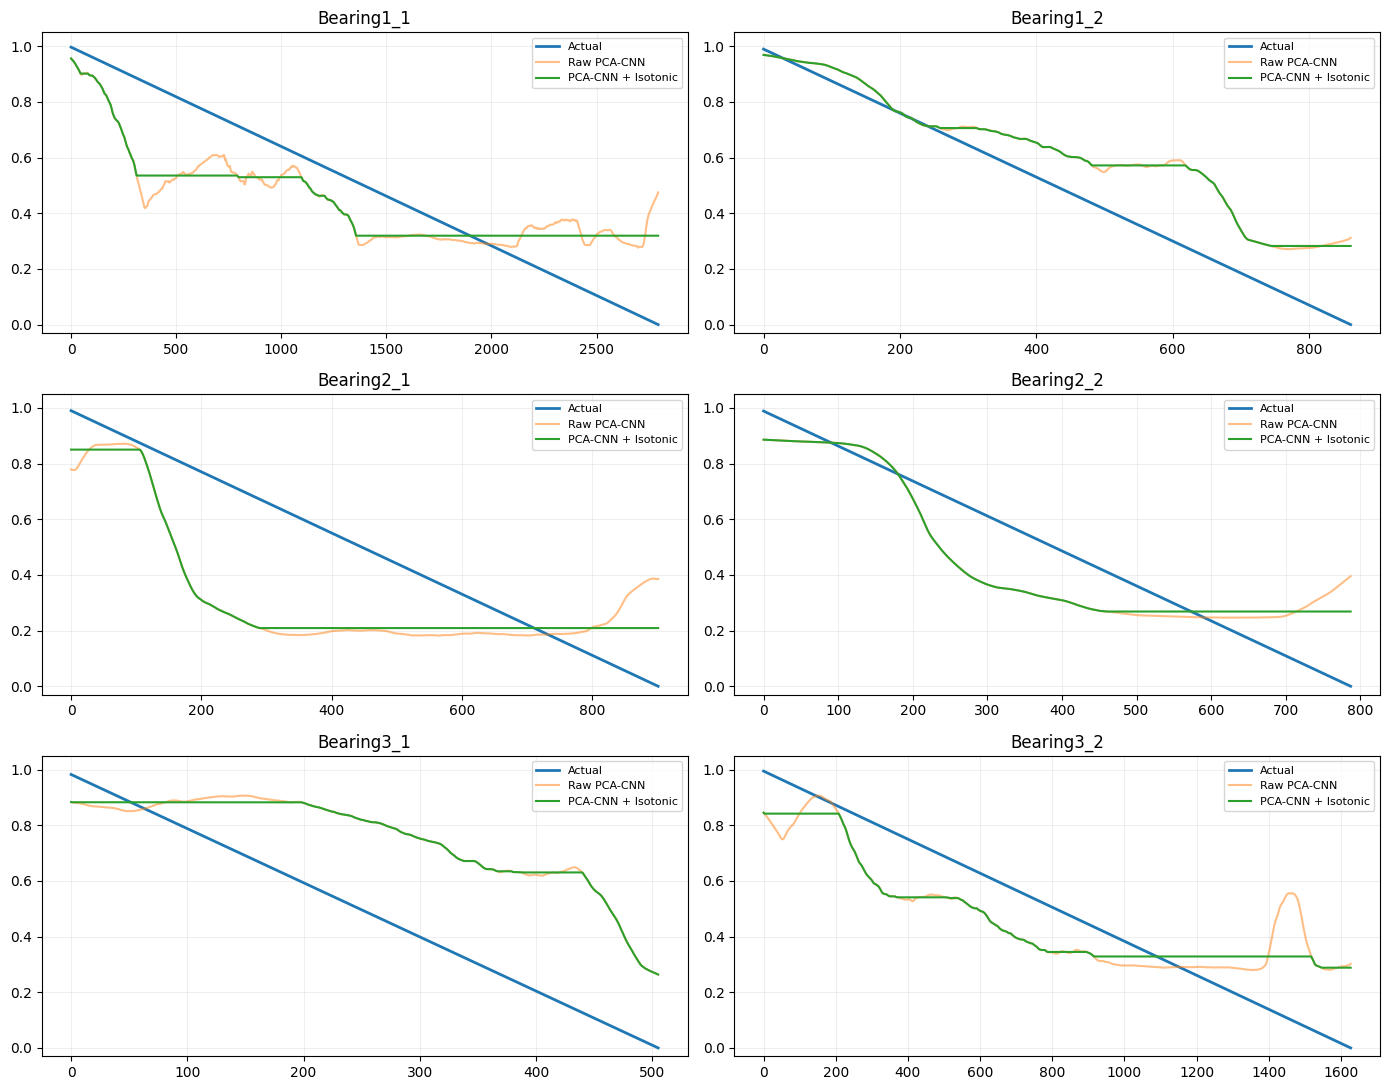

Saved six-fold validation results.


In [10]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.isotonic import IsotonicRegression
import copy, gc

lobo_results = []
lobo_predictions = []

for fold, heldout in enumerate(TRAIN_BEARINGS, 1):

    print(f"\nFold {fold}/6: {heldout}")

    fit_names = [n for n in TRAIN_BEARINGS if n != heldout]

    hi, pca, selected, scores = prepare_hi(
        fit_names, fit_names
    )

    Xtr, ytr = make_windows(
        fit_names, hi, train_labels
    )

    dl = DataLoader(
        TensorDataset(
            torch.tensor(Xtr, dtype=torch.float32),
            torch.tensor(ytr, dtype=torch.float32)
        ),
        batch_size=BS,
        shuffle=True,
        num_workers=0
    )

    model = HealthCNN().to(DEVICE)
    optimizer = torch.optim.Adam(
        model.parameters(), lr=LR
    )

    best_mae = float("inf")
    best_state = None
    best_epoch = 1
    wait = 0

    for epoch in range(1, 61):
        loss = train_hi_model(model, dl, optimizer)

        raw = predict_hi(model, hi[heldout])
        actual = train_labels[heldout][WIN-1:]

        val_mae = mean_absolute_error(actual, raw)

        if val_mae < best_mae:
            best_mae = val_mae
            best_epoch = epoch
            best_state = copy.deepcopy(model.state_dict())
            wait = 0
        else:
            wait += 1

        if epoch == 1 or epoch % 5 == 0:
            print(
                f"Epoch {epoch:02d} | "
                f"loss={loss:.5f} | MAE={val_mae:.5f}"
            )

        if wait >= 10:
            break

    model.load_state_dict(best_state)

    raw = predict_hi(model, hi[heldout])
    actual = train_labels[heldout][WIN-1:]

    iso = IsotonicRegression(
        increasing=False, y_min=0, y_max=1
    )

    corrected = iso.fit_transform(
        np.arange(len(raw)), raw
    )

    baseline = np.full_like(actual, 0.5)

    for method, pred in [
        ("Raw PCA-CNN", raw),
        ("PCA-CNN + Isotonic", corrected),
        ("Constant 0.5", baseline)
    ]:
        lobo_results.append({
            "bearing": heldout,
            "method": method,
            "best_epoch": best_epoch,
            "MAE": mean_absolute_error(actual, pred),
            "RMSE": np.sqrt(mean_squared_error(actual, pred)),
            "R2": r2_score(actual, pred)
        })

    for i in range(len(actual)):
        lobo_predictions.append({
            "bearing": heldout,
            "actual": actual[i],
            "raw": raw[i],
            "isotonic": corrected[i],
            "baseline": 0.5
        })

    print(
        f"Best epoch: {best_epoch} | "
        f"Raw MAE: {mean_absolute_error(actual, raw):.4f} | "
        f"Isotonic MAE: {mean_absolute_error(actual, corrected):.4f}"
    )

    del model, optimizer, dl
    gc.collect()

    if DEVICE.type == "cuda":
        torch.cuda.empty_cache()


lobo_df = pd.DataFrame(lobo_results)
lobo_pred_df = pd.DataFrame(lobo_predictions)

print("\nPER-BEARING RESULTS")
display(lobo_df.round(5))


summary = []

for method in lobo_df.method.unique():
    g = lobo_pred_df.copy()

    pred_col = {
        "Raw PCA-CNN": "raw",
        "PCA-CNN + Isotonic": "isotonic",
        "Constant 0.5": "baseline"
    }[method]

    actual = g["actual"].to_numpy()
    pred = g[pred_col].to_numpy()

    per = lobo_df[lobo_df.method == method]

    summary.append({
        "Model": method,
        "Pooled MAE": mean_absolute_error(actual, pred),
        "Pooled RMSE": np.sqrt(mean_squared_error(actual, pred)),
        "Pooled R2": r2_score(actual, pred),
        "Macro MAE": per.MAE.mean(),
        "Macro RMSE": per.RMSE.mean(),
        "Macro R2": per.R2.mean()
    })

lobo_summary = pd.DataFrame(summary)

print("\nSIX-FOLD LOBO SUMMARY")
display(lobo_summary.round(5))


fig, axes = plt.subplots(3, 2, figsize=(14, 11))

for ax, n in zip(axes.flat, TRAIN_BEARINGS):
    g = lobo_pred_df[lobo_pred_df.bearing == n]

    ax.plot(g.actual.values, label="Actual", linewidth=2)
    ax.plot(g.raw.values, label="Raw PCA-CNN", alpha=0.5)
    ax.plot(g.isotonic.values, label="PCA-CNN + Isotonic")
    ax.set_title(n)
    ax.set_ylim(-0.03, 1.05)
    ax.grid(alpha=0.2)
    ax.legend(fontsize=8)

plt.tight_layout()
plt.savefig(OUT / "pca_cnn_six_fold_lobo.png", dpi=300)
plt.show()


lobo_df.to_csv(OUT / "pca_cnn_lobo_per_bearing.csv", index=False)
lobo_pred_df.to_csv(OUT / "pca_cnn_lobo_predictions.csv", index=False)
lobo_summary.to_csv(OUT / "pca_cnn_lobo_summary.csv", index=False)

print("Saved six-fold validation results.")


Fold 1/6: Bearing1_1
Epoch 01 | loss=0.07348 | MAE=0.25527
Epoch 10 | loss=0.05363 | MAE=0.16410
Epoch 20 | loss=0.04571 | MAE=0.11731
Epoch 30 | loss=0.04428 | MAE=0.11500
Best epoch: 23 | Raw MAE: 0.1117 | Isotonic MAE: 0.1036

Fold 2/6: Bearing1_2
Epoch 01 | loss=0.07497 | MAE=0.24848
Epoch 10 | loss=0.04426 | MAE=0.30671
Best epoch: 1 | Raw MAE: 0.2485 | Isotonic MAE: 0.2477

Fold 3/6: Bearing2_1
Epoch 01 | loss=0.05527 | MAE=0.17176
Epoch 10 | loss=0.04297 | MAE=0.16506
Epoch 20 | loss=0.04054 | MAE=0.16046
Epoch 30 | loss=0.03970 | MAE=0.15934
Best epoch: 27 | Raw MAE: 0.1531 | Isotonic MAE: 0.1504

Fold 4/6: Bearing2_2
Epoch 01 | loss=0.06904 | MAE=0.25002
Epoch 10 | loss=0.04705 | MAE=0.20875
Epoch 20 | loss=0.04552 | MAE=0.19298
Epoch 30 | loss=0.04455 | MAE=0.18701
Epoch 40 | loss=0.04403 | MAE=0.18519
Epoch 50 | loss=0.04403 | MAE=0.18371
Best epoch: 47 | Raw MAE: 0.1801 | Isotonic MAE: 0.1666

Fold 5/6: Bearing3_1
Epoch 01 | loss=0.05618 | MAE=0.31736
Epoch 10 | loss=0.029

,bearing,method,best_epoch,features,MAE,RMSE,R2
0,Bearing1_1,Raw Strict PCA-CNN,23,6,0.11171,0.14495,0.74643
1,Bearing1_1,Strict PCA-CNN + Isotonic,23,6,0.10358,0.13808,0.76988
2,Bearing1_1,Constant 0.5,23,6,0.24929,0.28786,-0.00003
3,Bearing1_2,Raw Strict PCA-CNN,1,6,0.24848,0.28770,-0.01178
4,Bearing1_2,Strict PCA-CNN + Isotonic,1,6,0.24775,0.28658,-0.00393
5,Bearing1_2,Constant 0.5,1,6,0.24773,0.28607,-0.00033
6,Bearing2_1,Raw Strict PCA-CNN,27,6,0.15314,0.18432,0.58506
7,Bearing2_1,Strict PCA-CNN + Isotonic,27,6,0.15043,0.17958,0.60610
8,Bearing2_1,Constant 0.5,27,6,0.24783,0.28618,-0.00030
9,Bearing2_2,Raw Strict PCA-CNN,47,6,0.18009,0.20334,0.49369



STRICT LOBO SUMMARY


,Model,Pooled MAE,Pooled RMSE,Pooled R2,Macro MAE,Macro RMSE,Macro R2
0,Raw Strict PCA-CNN,0.17325,0.22041,0.40959,0.20214,0.24100,0.21387
1,Strict PCA-CNN + Isotonic,0.16834,0.21718,0.42673,0.19785,0.23731,0.23044
2,Constant 0.5,0.24843,0.28687,-0.00016,0.24789,0.28625,-0.00035


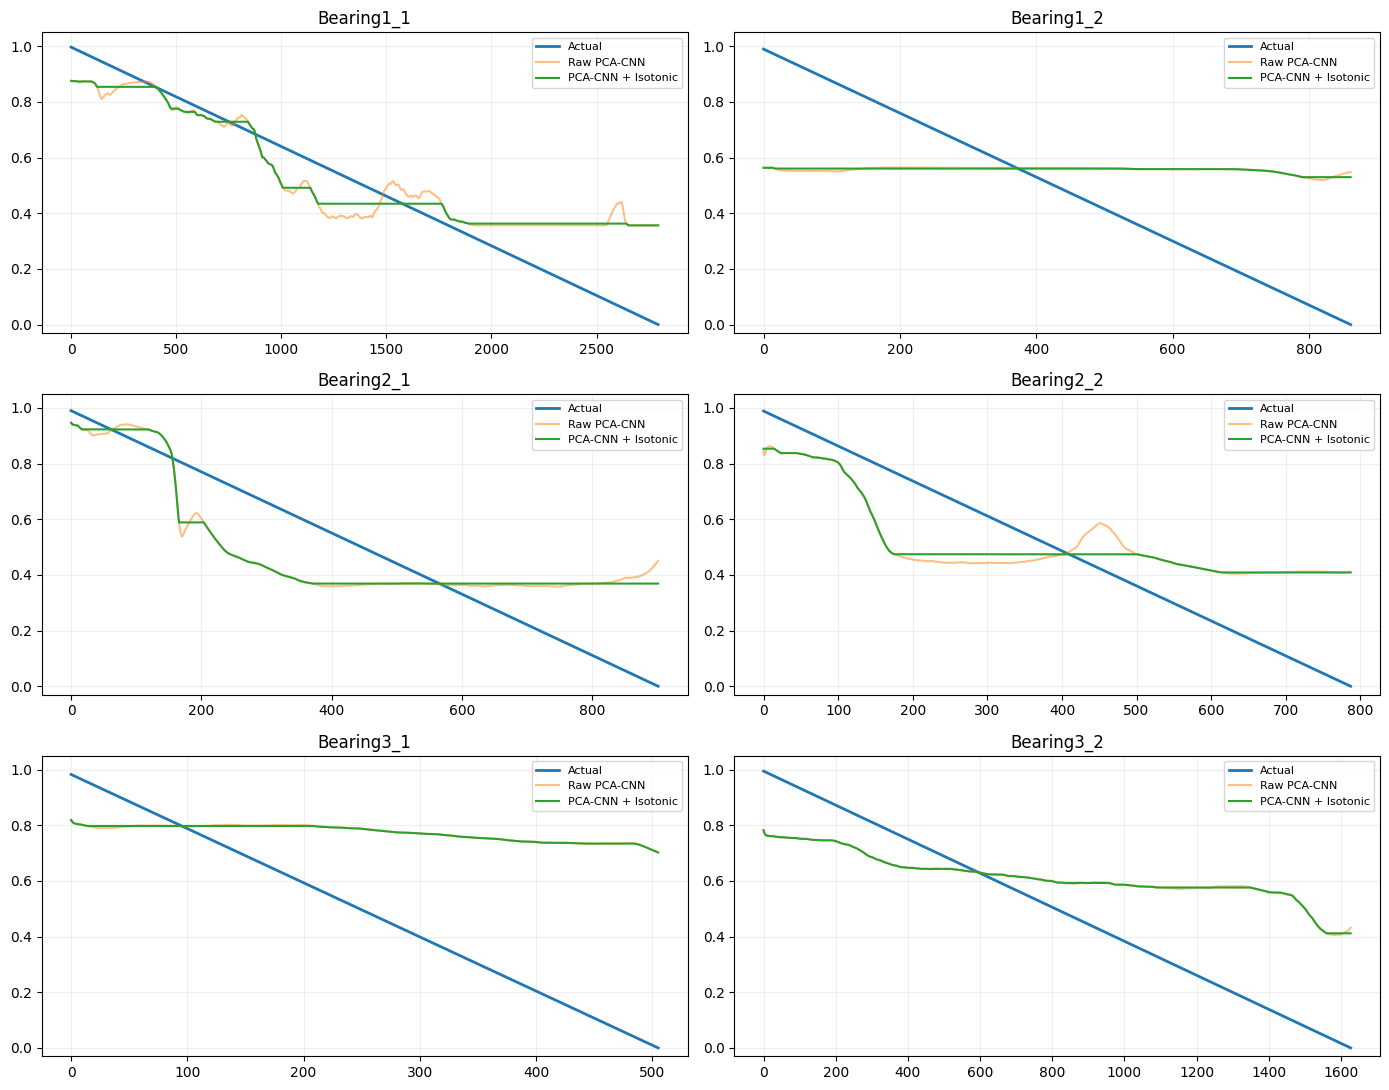

Saved to: /content/bearing_rul_cbam_only/strict_lobo


In [11]:
from sklearn.preprocessing import MinMaxScaler
from sklearn.decomposition import PCA
from sklearn.isotonic import IsotonicRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from scipy.stats import spearmanr
import copy, gc

strict_dir = OUT / "strict_lobo"
strict_dir.mkdir(exist_ok=True)

causal_bank = {
    n: pd.DataFrame(feature_bank[n]).rolling(
        100, min_periods=1
    ).mean().to_numpy(dtype=np.float32)
    for n in TRAIN_BEARINGS
}


def prepare_strict(train_names, heldout):

    scores = np.mean([
        [cori_score(causal_bank[n][:, j])
         for j in range(len(feature_names))]
        for n in train_names
    ], axis=0)

    selected = np.where(scores >= 0.5)[0]

    if len(selected) < 4:
        selected = np.argsort(scores)[-6:]

    selected = sorted(selected.tolist())

    scaler = MinMaxScaler()
    scaler.fit(np.concatenate([
        causal_bank[n][:, selected] for n in train_names
    ]))

    xs = {
        n: scaler.transform(
            causal_bank[n][:, selected]
        ).astype(np.float32)
        for n in train_names + [heldout]
    }

    pca = PCA(n_components=1)
    pca.fit(np.concatenate([xs[n] for n in train_names]))

    correlations = []

    for n in train_names:
        z = pca.transform(xs[n]).ravel()
        r = spearmanr(np.arange(len(z)), z).statistic
        correlations.append(r if np.isfinite(r) else 0)

    direction = -1 if np.mean(correlations) > 0 else 1

    train_pc = np.concatenate([
        pca.transform(xs[n]).ravel() * direction
        for n in train_names
    ])

    lo, hi = train_pc.min(), train_pc.max()

    health = {
        n: np.clip(
            (pca.transform(xs[n]).ravel() * direction - lo)
            / (hi - lo + 1e-8),
            0, 1
        ).astype(np.float32)
        for n in train_names + [heldout]
    }

    return health, selected


strict_rows = []
strict_preds = []

for fold, heldout in enumerate(TRAIN_BEARINGS, 1):

    print(f"\nFold {fold}/6: {heldout}")

    train_names = [
        n for n in TRAIN_BEARINGS if n != heldout
    ]

    hi, selected = prepare_strict(train_names, heldout)

    Xtr, ytr = make_windows(
        train_names, hi, train_labels
    )

    dl = DataLoader(
        TensorDataset(
            torch.tensor(Xtr, dtype=torch.float32),
            torch.tensor(ytr, dtype=torch.float32)
        ),
        batch_size=BS,
        shuffle=True,
        num_workers=0
    )

    torch.manual_seed(SEED + fold)

    model = HealthCNN().to(DEVICE)
    optimizer = torch.optim.Adam(model.parameters(), lr=LR)

    best_mae = float("inf")
    best_state = None
    best_epoch = 1
    wait = 0

    for epoch in range(1, 81):

        loss = train_hi_model(model, dl, optimizer)

        raw = predict_hi(model, hi[heldout])
        actual = train_labels[heldout][WIN-1:]

        val_mae = mean_absolute_error(actual, raw)

        if val_mae < best_mae:
            best_mae = val_mae
            best_epoch = epoch
            best_state = copy.deepcopy(model.state_dict())
            wait = 0
        else:
            wait += 1

        if epoch == 1 or epoch % 10 == 0:
            print(
                f"Epoch {epoch:02d} | loss={loss:.5f} | "
                f"MAE={val_mae:.5f}"
            )

        if wait >= 12:
            break

    model.load_state_dict(best_state)

    raw = predict_hi(model, hi[heldout])
    actual = train_labels[heldout][WIN-1:]

    iso = IsotonicRegression(
        increasing=False, y_min=0, y_max=1
    )

    corrected = iso.fit_transform(
        np.arange(len(raw)), raw
    )

    baseline = np.full_like(actual, 0.5)

    for method, pred in [
        ("Raw Strict PCA-CNN", raw),
        ("Strict PCA-CNN + Isotonic", corrected),
        ("Constant 0.5", baseline)
    ]:
        strict_rows.append({
            "bearing": heldout,
            "method": method,
            "best_epoch": best_epoch,
            "features": len(selected),
            "MAE": mean_absolute_error(actual, pred),
            "RMSE": np.sqrt(mean_squared_error(actual, pred)),
            "R2": r2_score(actual, pred)
        })

    for i in range(len(actual)):
        strict_preds.append({
            "bearing": heldout,
            "actual": actual[i],
            "raw": raw[i],
            "isotonic": corrected[i],
            "baseline": 0.5
        })

    print(
        f"Best epoch: {best_epoch} | "
        f"Raw MAE: {mean_absolute_error(actual, raw):.4f} | "
        f"Isotonic MAE: {mean_absolute_error(actual, corrected):.4f}"
    )

    torch.save(
        best_state,
        strict_dir / f"{heldout}.pt"
    )

    del model, optimizer, dl
    gc.collect()

    if DEVICE.type == "cuda":
        torch.cuda.empty_cache()


strict_df = pd.DataFrame(strict_rows)
strict_pred_df = pd.DataFrame(strict_preds)

print("\nPER-BEARING RESULTS")
display(strict_df.round(5))


summary = []

for method in strict_df.method.unique():

    g = strict_df[strict_df.method == method]

    col = {
        "Raw Strict PCA-CNN": "raw",
        "Strict PCA-CNN + Isotonic": "isotonic",
        "Constant 0.5": "baseline"
    }[method]

    actual = strict_pred_df.actual.to_numpy()
    pred = strict_pred_df[col].to_numpy()

    summary.append({
        "Model": method,
        "Pooled MAE": mean_absolute_error(actual, pred),
        "Pooled RMSE": np.sqrt(mean_squared_error(actual, pred)),
        "Pooled R2": r2_score(actual, pred),
        "Macro MAE": g.MAE.mean(),
        "Macro RMSE": g.RMSE.mean(),
        "Macro R2": g.R2.mean()
    })

strict_summary = pd.DataFrame(summary)

print("\nSTRICT LOBO SUMMARY")
display(strict_summary.round(5))


fig, axes = plt.subplots(3, 2, figsize=(14, 11))

for ax, name in zip(axes.flat, TRAIN_BEARINGS):
    g = strict_pred_df[strict_pred_df.bearing == name]

    ax.plot(g.actual.values, label="Actual", linewidth=2)
    ax.plot(g.raw.values, label="Raw PCA-CNN", alpha=0.5)
    ax.plot(g.isotonic.values, label="PCA-CNN + Isotonic")

    ax.set_title(name)
    ax.set_ylim(-0.03, 1.05)
    ax.grid(alpha=0.2)
    ax.legend(fontsize=8)

plt.tight_layout()
plt.savefig(strict_dir / "strict_lobo_curves.png", dpi=300)
plt.show()

strict_df.to_csv(strict_dir / "per_bearing.csv", index=False)
strict_pred_df.to_csv(strict_dir / "predictions.csv", index=False)
strict_summary.to_csv(strict_dir / "summary.csv", index=False)

print("Saved to:", strict_dir)

Bearing1_1 (2803, 42)
Bearing1_2 (871, 42)
Bearing2_1 (911, 42)
Bearing2_2 (797, 42)
Bearing3_1 (515, 42)
Bearing3_2 (1637, 42)
Bearing1_3 (2375, 42)
Bearing1_4 (1428, 42)
Bearing1_5 (2463, 42)
Bearing1_7 (2259, 42)
Bearing2_3 (1955, 42)
Bearing2_6 (701, 42)

Fold 1/6: Bearing1_1
Epoch 01 | loss=0.15019 | val MAE=0.31009 | best
Epoch 05 | loss=0.04361 | val MAE=0.08310 | best
Epoch 10 | loss=0.01645 | val MAE=0.10722 | wait 2/12
Epoch 15 | loss=0.01022 | val MAE=0.08763 | wait 7/12
Epoch 20 | loss=0.00659 | val MAE=0.08058 | best
Epoch 25 | loss=0.00465 | val MAE=0.08342 | wait 4/12
Epoch 30 | loss=0.00518 | val MAE=0.08343 | wait 1/12
Epoch 35 | loss=0.00391 | val MAE=0.07241 | wait 6/12
Epoch 40 | loss=0.00341 | val MAE=0.07619 | wait 3/12
Epoch 45 | loss=0.00301 | val MAE=0.07786 | wait 4/12
Epoch 50 | loss=0.00305 | val MAE=0.08548 | wait 9/12
Best epoch: 41 | Raw MAE: 0.06674 | Isotonic MAE: 0.04885

Fold 2/6: Bearing1_2
Epoch 01 | loss=0.12328 | val MAE=0.25445 | best
Epoch 05 | 

,bearing,method,best_epoch,MAE,RMSE,R2
0,Bearing1_1,Raw,41,0.06674,0.09062,0.89931
1,Bearing1_1,Isotonic,41,0.04885,0.06215,0.95264
2,Bearing1_2,Raw,1,0.25445,0.30930,-0.23144
3,Bearing1_2,Isotonic,1,0.25416,0.30886,-0.22796
4,Bearing2_1,Raw,3,0.12678,0.15559,0.68936
5,Bearing2_1,Isotonic,3,0.12634,0.15240,0.70195
6,Bearing2_2,Raw,2,0.09717,0.11673,0.82342
7,Bearing2_2,Isotonic,2,0.09654,0.11313,0.83415
8,Bearing3_1,Raw,5,0.28314,0.35192,-0.67610
9,Bearing3_1,Isotonic,5,0.28313,0.35109,-0.66822


,Model,Pooled MAE,Pooled RMSE,Pooled R2,Macro MAE,Macro RMSE,Macro R2
0,Raw,0.14838,0.20908,0.45011,0.17629,0.21745,0.25407
1,Isotonic,0.13263,0.18793,0.55572,0.16633,0.20152,0.33029



Final training epochs: 8

Final model seed: 2028
Epoch 1/8 | loss=0.11307
Epoch 5/8 | loss=0.01623

Final model seed: 2045
Epoch 1/8 | loss=0.14210
Epoch 5/8 | loss=0.01603

Final model seed: 2062
Epoch 1/8 | loss=0.13824
Epoch 5/8 | loss=0.01368

TEST PER-BEARING RESULTS


,bearing,method,MAE,RMSE,R2
0,Bearing1_3,Raw,0.06921,0.08617,0.90861
1,Bearing1_3,Isotonic,0.06905,0.08579,0.90941
2,Bearing1_4,Raw,0.05790,0.06862,0.94104
3,Bearing1_4,Isotonic,0.05695,0.06760,0.94278
4,Bearing1_5,Raw,0.20671,0.27097,0.09705
5,Bearing1_5,Isotonic,0.19941,0.25743,0.18502
6,Bearing1_7,Raw,0.22165,0.28375,0.00767
7,Bearing1_7,Isotonic,0.14837,0.18877,0.56078
8,Bearing2_3,Raw,0.19001,0.23822,0.29764
9,Bearing2_3,Isotonic,0.17449,0.22841,0.35424



TEST SUMMARY


,Model,Pooled MAE,Pooled RMSE,Pooled R2,Macro MAE,Macro RMSE,Macro R2
0,Raw,0.15212,0.21316,0.43695,0.14100,0.17670,0.51438
1,Isotonic,0.13279,0.18418,0.57964,0.12479,0.15666,0.63136


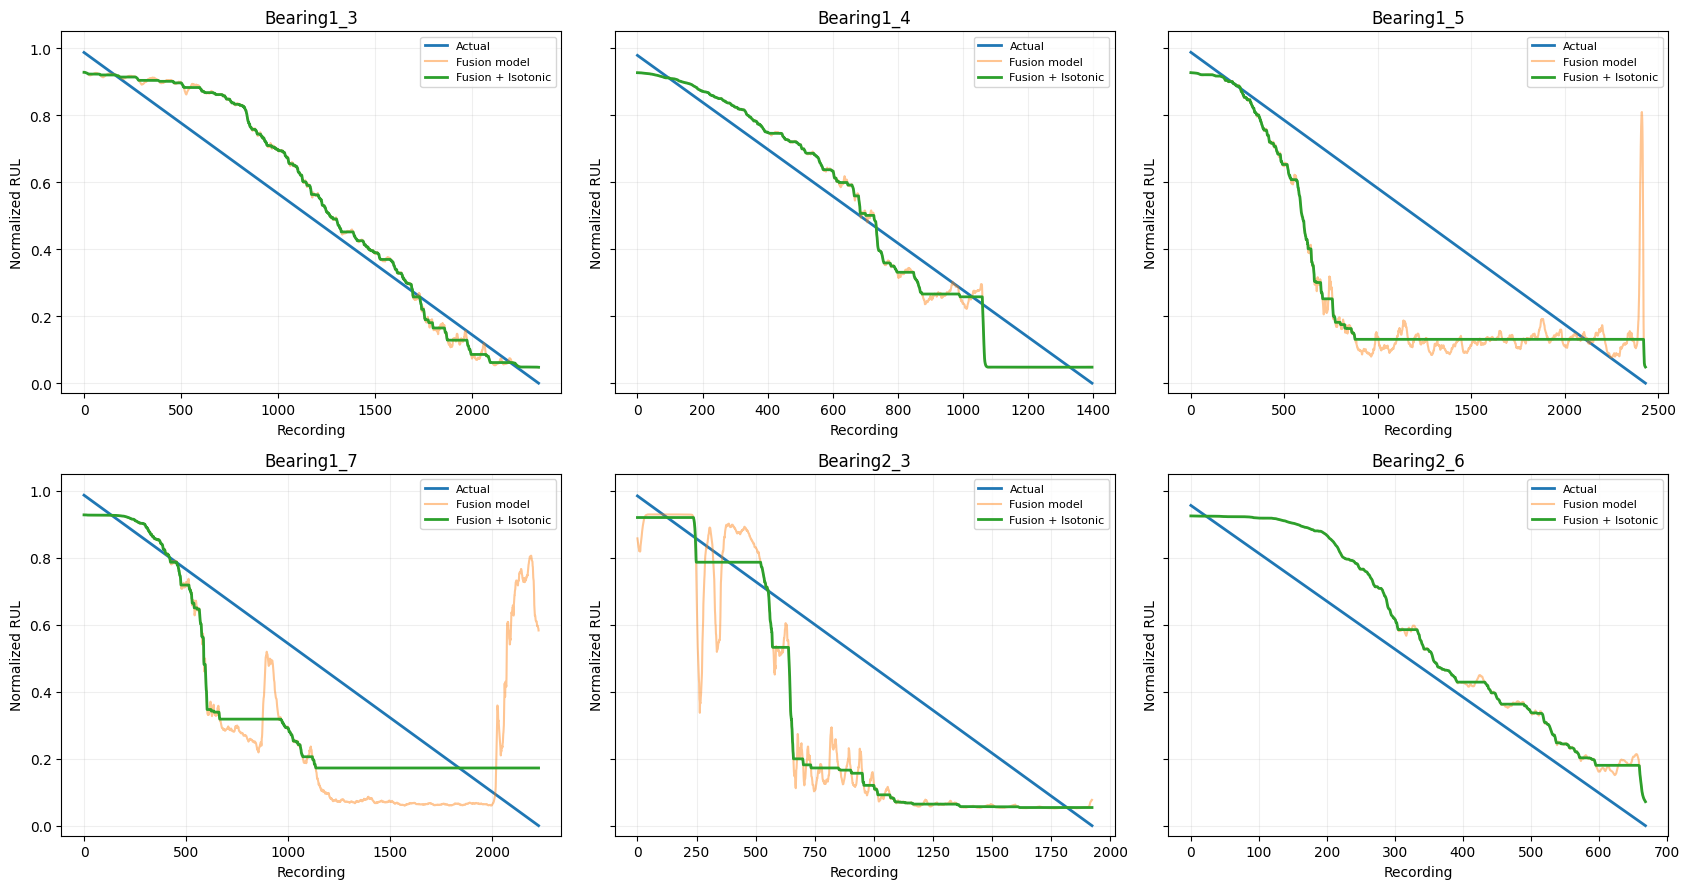


Experiment complete.
Saved to: /content/bearing_rul_cbam_only/wavelet_fusion_tcn_big
Best fold epochs: [41, 1, 3, 2, 5, 2]
Final training epochs: 8


In [12]:
!pip -q install PyWavelets

import pywt
import gc
import copy
from scipy.stats import skew, kurtosis
from sklearn.preprocessing import StandardScaler
from sklearn.isotonic import IsotonicRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from torch.utils.data import Dataset, DataLoader, WeightedRandomSampler

EXP = OUT / "wavelet_fusion_tcn_big"
EXP.mkdir(parents=True, exist_ok=True)

WIN = 32
TRAIN_STRIDE = 3
BS = 128
MAX_EPOCHS = 80
PATIENCE = 12
SEEDS = [2028, 2045, 2062]

time_names = [
    "mean", "std", "rms", "variance", "mean_abs",
    "peak", "peak_to_peak", "skew", "kurtosis",
    "crest", "impulse", "shape", "clearance",
    "zero_crossing", "log_energy"
]

freq_names = [
    "centroid", "spread", "rms_freq", "entropy",
    "rolloff", "peak_freq", "flatness"
]

wpt_names = (
    [f"wpt_{i}" for i in range(16)] +
    ["wpt_entropy", "wpt_top2", "wpt_centroid", "wpt_max"]
)

feat_names = time_names + freq_names + wpt_names


def extract_features(path):
    x = read_signal(path).astype(np.float64)
    x -= x.mean()
    eps = 1e-10

    rms = np.sqrt(np.mean(x**2))
    mean_abs = np.mean(np.abs(x))
    peak = np.max(np.abs(x))
    sqrt_abs = np.mean(np.sqrt(np.abs(x)))

    tf = [
        np.mean(x),
        np.std(x),
        rms,
        np.var(x),
        mean_abs,
        peak,
        np.ptp(x),
        skew(x, bias=False),
        kurtosis(x, fisher=True, bias=False),
        peak / (rms + eps),
        peak / (mean_abs + eps),
        rms / (mean_abs + eps),
        peak / (sqrt_abs**2 + eps),
        np.mean(np.diff(np.signbit(x)) != 0),
        np.log(np.mean(x**2) + eps)
    ]

    spec = np.abs(np.fft.rfft(x))**2
    freq = np.fft.rfftfreq(len(x), d=1/25600) / 12800
    prob = spec / (spec.sum() + eps)

    centroid = np.sum(freq * prob)
    spread = np.sqrt(np.sum((freq-centroid)**2 * prob))
    rms_freq = np.sqrt(np.sum(freq**2 * prob))
    entropy = -np.sum(prob * np.log(prob + eps)) / np.log(len(prob))
    rolloff = freq[min(np.searchsorted(np.cumsum(prob), 0.85), len(freq)-1)]
    peak_freq = freq[np.argmax(spec)]
    flatness = np.exp(np.mean(np.log(spec + eps))) / (np.mean(spec) + eps)

    ff = [
        centroid, spread, rms_freq, entropy,
        rolloff, peak_freq, flatness
    ]

    packet = pywt.WaveletPacket(
        data=x, wavelet="db4", mode="symmetric", maxlevel=4
    )

    nodes = packet.get_level(4, order="freq")
    energy = np.array([
        np.sum(np.asarray(node.data)**2) for node in nodes
    ])

    en = energy / (energy.sum() + eps)
    wpt = list(en) + [
        -np.sum(en * np.log(en + eps)) / np.log(len(en)),
        np.sort(en)[-2:].sum(),
        np.sum(np.arange(16) * en) / 15,
        en.max()
    ]

    return np.nan_to_num(
        np.asarray(tf + ff + wpt, dtype=np.float32)
    )


# Feature extraction

features = {}

for name in TRAIN_BEARINGS + TEST_BEARINGS:
    folder = (
        LEARNING_DIR / name
        if name in TRAIN_BEARINGS
        else FULL_TEST_DIR / name
    )

    files = get_files(folder)

    features[name] = np.stack([
        extract_features(p) for p in files
    ])

    print(name, features[name].shape)

assert features[TRAIN_BEARINGS[0]].shape[1] == 42

np.savez_compressed(EXP / "features.npz", **features)


class SequenceDataset(Dataset):
    def __init__(self, data, labels, names, stride=1):
        self.data = data
        self.labels = labels
        self.items = []
        counts = {}

        for n in names:
            ends = list(range(WIN-1, len(data[n]), stride))
            counts[n] = len(ends)
            self.items.extend((n, e) for e in ends)

        self.weights = torch.tensor([
            1.0 / counts[n] for n, _ in self.items
        ], dtype=torch.double)

    def __len__(self):
        return len(self.items)

    def __getitem__(self, i):
        n, e = self.items[i]

        x = self.data[n][e-WIN+1:e+1]
        y = self.labels[n][e]

        return (
            torch.tensor(x, dtype=torch.float32),
            torch.tensor(y, dtype=torch.float32)
        )


class ResidualTCN(nn.Module):
    def __init__(self, channels=128, dilation=1):
        super().__init__()

        self.net = nn.Sequential(
            nn.Conv1d(
                channels, channels, 3,
                padding=dilation, dilation=dilation
            ),
            nn.GroupNorm(8, channels),
            nn.GELU(),
            nn.Dropout(0.12),
            nn.Conv1d(channels, channels, 1),
            nn.GroupNorm(8, channels)
        )

    def forward(self, x):
        return F.gelu(x + self.net(x))


class FusionTCNBiGRU(nn.Module):
    def __init__(self):
        super().__init__()

        self.time_branch = nn.Sequential(
            nn.Linear(15, 64),
            nn.LayerNorm(64),
            nn.GELU(),
            nn.Dropout(0.1),
            nn.Linear(64, 48),
            nn.LayerNorm(48)
        )

        self.freq_branch = nn.Sequential(
            nn.Linear(7, 48),
            nn.LayerNorm(48),
            nn.GELU(),
            nn.Linear(48, 48),
            nn.LayerNorm(48)
        )

        self.wave_branch = nn.Sequential(
            nn.Linear(20, 64),
            nn.LayerNorm(64),
            nn.GELU(),
            nn.Dropout(0.1),
            nn.Linear(64, 48),
            nn.LayerNorm(48)
        )

        self.gate = nn.Sequential(
            nn.Linear(144, 144),
            nn.Sigmoid()
        )

        self.fuse = nn.Sequential(
            nn.Linear(144, 128),
            nn.LayerNorm(128),
            nn.GELU(),
            nn.Dropout(0.15)
        )

        self.tcn = nn.ModuleList([
            ResidualTCN(128, d) for d in [1, 2, 4, 8, 16]
        ])

        self.gru = nn.GRU(
            128, 96,
            num_layers=2,
            batch_first=True,
            bidirectional=True,
            dropout=0.15
        )

        self.attention = nn.MultiheadAttention(
            192, 4, dropout=0.15, batch_first=True
        )

        self.norm = nn.LayerNorm(192)

        self.pool_score = nn.Sequential(
            nn.Linear(192, 64),
            nn.Tanh(),
            nn.Linear(64, 1)
        )

        self.head = nn.Sequential(
            nn.Linear(192, 96),
            nn.LayerNorm(96),
            nn.GELU(),
            nn.Dropout(0.2),
            nn.Linear(96, 48),
            nn.GELU(),
            nn.Linear(48, 1)
        )

    def forward(self, x):
        t = self.time_branch(x[:, :, :15])
        f = self.freq_branch(x[:, :, 15:22])
        w = self.wave_branch(x[:, :, 22:])

        z = torch.cat([t, f, w], dim=-1)
        z = self.fuse(z * self.gate(z))

        z = z.transpose(1, 2)

        for block in self.tcn:
            z = block(z)

        z = z.transpose(1, 2)

        z, _ = self.gru(z)

        a, _ = self.attention(z, z, z, need_weights=False)
        z = self.norm(z + a)

        weights = torch.softmax(
            self.pool_score(z).squeeze(-1), dim=1
        )

        z = torch.sum(z * weights.unsqueeze(-1), dim=1)

        return torch.sigmoid(self.head(z)).squeeze(-1)


def scale_features(names, fit_names):
    scaler = StandardScaler()

    scaler.fit(np.concatenate([
        features[n] for n in fit_names
    ]))

    scaled = {
        n: np.nan_to_num(
            scaler.transform(features[n]).astype(np.float32)
        )
        for n in names
    }

    return scaled, scaler


def fit_epoch(model, loader, optimizer):
    model.train()
    losses = []

    for xb, yb in loader:
        xb = xb.to(DEVICE)
        yb = yb.to(DEVICE)

        optimizer.zero_grad(set_to_none=True)
        pred = model(xb)

        loss = F.smooth_l1_loss(pred, yb, beta=0.08)
        loss.backward()

        torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
        optimizer.step()

        losses.append(loss.item())

    return float(np.mean(losses))


def predict_dataset(model, loader):
    model.eval()
    pp, yy = [], []

    with torch.no_grad():
        for xb, yb in loader:
            pred = model(xb.to(DEVICE))

            pp.extend(pred.cpu().numpy())
            yy.extend(yb.numpy())

    return np.asarray(pp), np.asarray(yy)


def get_metrics(y, p):
    return {
        "MAE": mean_absolute_error(y, p),
        "RMSE": np.sqrt(mean_squared_error(y, p)),
        "R2": r2_score(y, p)
    }


# Six-fold LOBO

fold_rows = []
oof_rows = []
best_epochs = []

for fold, heldout in enumerate(TRAIN_BEARINGS, 1):

    print(f"\n{'='*55}\nFold {fold}/6: {heldout}\n{'='*55}")

    fit_names = [n for n in TRAIN_BEARINGS if n != heldout]

    scaled, scaler = scale_features(
        TRAIN_BEARINGS, fit_names
    )

    train_ds = SequenceDataset(
        scaled, train_labels, fit_names, TRAIN_STRIDE
    )

    sampler = WeightedRandomSampler(
        train_ds.weights, len(train_ds), replacement=True
    )

    train_dl = DataLoader(
        train_ds, batch_size=BS,
        sampler=sampler, num_workers=0,
        pin_memory=DEVICE.type == "cuda"
    )

    val_ds = SequenceDataset(
        scaled, train_labels, [heldout], 1
    )

    val_dl = DataLoader(
        val_ds, batch_size=256, shuffle=False
    )

    torch.manual_seed(SEED + fold)

    model = FusionTCNBiGRU().to(DEVICE)
    optimizer = torch.optim.AdamW(
        model.parameters(), lr=4e-4, weight_decay=1e-4
    )

    best_mae = float("inf")
    best_state = None
    best_epoch = 1
    wait = 0

    for epoch in range(1, MAX_EPOCHS + 1):
        loss = fit_epoch(model, train_dl, optimizer)

        vp, vy = predict_dataset(model, val_dl)
        val_mae = mean_absolute_error(vy, vp)

        if val_mae < best_mae:
            best_mae = val_mae
            best_epoch = epoch
            best_state = {
                k: v.detach().cpu().clone()
                for k, v in model.state_dict().items()
            }
            wait = 0
            status = "best"
        else:
            wait += 1
            status = f"wait {wait}/{PATIENCE}"

        if epoch == 1 or epoch % 5 == 0:
            print(
                f"Epoch {epoch:02d} | loss={loss:.5f} | "
                f"val MAE={val_mae:.5f} | {status}"
            )

        if wait >= PATIENCE:
            break

    best_epochs.append(best_epoch)

    model.load_state_dict(best_state)
    vp, vy = predict_dataset(model, val_dl)

    iso = IsotonicRegression(
        increasing=False, y_min=0, y_max=1
    )
    vi = iso.fit_transform(np.arange(len(vp)), vp)

    for method, pred in [
        ("Raw", vp),
        ("Isotonic", vi)
    ]:
        m = get_metrics(vy, pred)

        fold_rows.append({
            "bearing": heldout,
            "method": method,
            "best_epoch": best_epoch,
            **m
        })

    for i in range(len(vy)):
        oof_rows.append({
            "bearing": heldout,
            "actual": vy[i],
            "raw": vp[i],
            "isotonic": vi[i]
        })

    torch.save(
        best_state, EXP / f"fold_{fold}_{heldout}.pt"
    )

    pd.DataFrame(fold_rows).to_csv(
        EXP / "lobo_per_bearing.csv", index=False
    )

    pd.DataFrame(oof_rows).to_csv(
        EXP / "lobo_predictions.csv", index=False
    )

    print(
        f"Best epoch: {best_epoch} | "
        f"Raw MAE: {get_metrics(vy, vp)['MAE']:.5f} | "
        f"Isotonic MAE: {get_metrics(vy, vi)['MAE']:.5f}"
    )

    del model, optimizer, train_dl, val_dl
    gc.collect()

    if DEVICE.type == "cuda":
        torch.cuda.empty_cache()


fold_df = pd.DataFrame(fold_rows)
oof_df = pd.DataFrame(oof_rows)

lobo_summary = []

for method, col in [("Raw", "raw"), ("Isotonic", "isotonic")]:
    pred = oof_df[col].to_numpy()
    actual = oof_df.actual.to_numpy()
    g = fold_df[fold_df.method == method]

    lobo_summary.append({
        "Model": method,
        "Pooled MAE": mean_absolute_error(actual, pred),
        "Pooled RMSE": np.sqrt(mean_squared_error(actual, pred)),
        "Pooled R2": r2_score(actual, pred),
        "Macro MAE": g.MAE.mean(),
        "Macro RMSE": g.RMSE.mean(),
        "Macro R2": g.R2.mean()
    })

lobo_summary = pd.DataFrame(lobo_summary)

print("\nSIX-FOLD LOBO RESULTS")
display(fold_df.round(5))
display(lobo_summary.round(5))


# Final three-seed training

final_epochs = max(8, int(np.median(best_epochs)))

print("\nFinal training epochs:", final_epochs)

scaled_all, final_scaler = scale_features(
    TRAIN_BEARINGS + TEST_BEARINGS, TRAIN_BEARINGS
)

final_ds = SequenceDataset(
    scaled_all, train_labels, TRAIN_BEARINGS, TRAIN_STRIDE
)

final_sampler = WeightedRandomSampler(
    final_ds.weights, len(final_ds), replacement=True
)

final_dl = DataLoader(
    final_ds, batch_size=BS,
    sampler=final_sampler, num_workers=0
)

test_pred_seeds = {n: [] for n in TEST_BEARINGS}

for seed in SEEDS:
    print(f"\nFinal model seed: {seed}")

    torch.manual_seed(seed)

    model = FusionTCNBiGRU().to(DEVICE)
    optimizer = torch.optim.AdamW(
        model.parameters(), lr=4e-4, weight_decay=1e-4
    )

    for epoch in range(1, final_epochs + 1):
        loss = fit_epoch(model, final_dl, optimizer)

        if epoch == 1 or epoch % 5 == 0:
            print(
                f"Epoch {epoch}/{final_epochs} | loss={loss:.5f}"
            )

    model.eval()

    torch.save(
        model.state_dict(),
        EXP / f"final_seed_{seed}.pt"
    )

    for n in TEST_BEARINGS:
        ds = SequenceDataset(
            scaled_all, test_labels, [n], 1
        )
        dl = DataLoader(ds, batch_size=256, shuffle=False)

        p, _ = predict_dataset(model, dl)
        test_pred_seeds[n].append(p)

    del model, optimizer
    gc.collect()

    if DEVICE.type == "cuda":
        torch.cuda.empty_cache()


# Ensemble and isotonic evaluation

test_curves = {}
test_rows = []

for n in TEST_BEARINGS:
    raw = np.mean(test_pred_seeds[n], axis=0)
    actual = test_labels[n][WIN-1:]

    iso = IsotonicRegression(
        increasing=False, y_min=0, y_max=1
    )

    corrected = iso.fit_transform(
        np.arange(len(raw)), raw
    )

    test_curves[n] = {
        "actual": actual,
        "raw": raw,
        "isotonic": corrected
    }

    for method, pred in [
        ("Raw", raw),
        ("Isotonic", corrected)
    ]:
        test_rows.append({
            "bearing": n,
            "method": method,
            **get_metrics(actual, pred)
        })


test_df = pd.DataFrame(test_rows)
summary_rows = []

for method, col in [("Raw", "raw"), ("Isotonic", "isotonic")]:
    actual = np.concatenate([
        test_curves[n]["actual"] for n in TEST_BEARINGS
    ])

    pred = np.concatenate([
        test_curves[n][col] for n in TEST_BEARINGS
    ])

    g = test_df[test_df.method == method]

    summary_rows.append({
        "Model": method,
        "Pooled MAE": mean_absolute_error(actual, pred),
        "Pooled RMSE": np.sqrt(mean_squared_error(actual, pred)),
        "Pooled R2": r2_score(actual, pred),
        "Macro MAE": g.MAE.mean(),
        "Macro RMSE": g.RMSE.mean(),
        "Macro R2": g.R2.mean()
    })


test_summary = pd.DataFrame(summary_rows)

print("\nTEST PER-BEARING RESULTS")
display(test_df.round(5))

print("\nTEST SUMMARY")
display(test_summary.round(5))


# Plots

fig, axes = plt.subplots(2, 3, figsize=(17, 9), sharey=True)

for ax, n in zip(axes.flat, TEST_BEARINGS):
    d = test_curves[n]

    ax.plot(d["actual"], label="Actual", linewidth=2)
    ax.plot(d["raw"], label="Fusion model", alpha=0.45)
    ax.plot(d["isotonic"], label="Fusion + Isotonic", linewidth=2)

    ax.set_title(n)
    ax.set_xlabel("Recording")
    ax.set_ylabel("Normalized RUL")
    ax.set_ylim(-0.03, 1.05)
    ax.legend(fontsize=8)
    ax.grid(alpha=0.2)

plt.tight_layout()
plt.savefig(EXP / "test_trajectories.png", dpi=300)
plt.show()


pd.DataFrame({
    "epoch": np.arange(1, len(best_epochs)+1),
    "best_epoch": best_epochs
}).to_csv(EXP / "fold_epochs.csv", index=False)

fold_df.to_csv(EXP / "lobo_per_bearing.csv", index=False)
oof_df.to_csv(EXP / "lobo_predictions.csv", index=False)
lobo_summary.to_csv(EXP / "lobo_summary.csv", index=False)
test_df.to_csv(EXP / "test_per_bearing.csv", index=False)
test_summary.to_csv(EXP / "test_summary.csv", index=False)

joblib.dump(final_scaler, EXP / "feature_scaler.joblib")

pd.DataFrame({
    "bearing": np.concatenate([
        np.repeat(n, len(test_curves[n]["raw"]))
        for n in TEST_BEARINGS
    ]),
    "actual": np.concatenate([
        test_curves[n]["actual"] for n in TEST_BEARINGS
    ]),
    "raw_prediction": np.concatenate([
        test_curves[n]["raw"] for n in TEST_BEARINGS
    ]),
    "isotonic_prediction": np.concatenate([
        test_curves[n]["isotonic"] for n in TEST_BEARINGS
    ])
}).to_csv(EXP / "test_predictions.csv", index=False)

print("\nExperiment complete.")
print("Saved to:", EXP)
print("Best fold epochs:", best_epochs)
print("Final training epochs:", final_epochs)


Fold 1/6: Bearing1_1

Seed: 2028
Epoch 01 | loss=0.15019 | MAE=0.31009 | best
Epoch 10 | loss=0.01645 | MAE=0.10722 | wait 2/12
Epoch 20 | loss=0.00659 | MAE=0.08058 | best
Epoch 30 | loss=0.00518 | MAE=0.08343 | wait 1/12
Epoch 40 | loss=0.00341 | MAE=0.07619 | wait 3/12
Epoch 50 | loss=0.00305 | MAE=0.08548 | wait 9/12
Best epoch: 41 | Raw MAE: 0.06674 | Isotonic MAE: 0.04885

Seed: 2045
Epoch 01 | loss=0.14971 | MAE=0.18635 | best
Epoch 10 | loss=0.01196 | MAE=0.11530 | wait 2/12
Epoch 20 | loss=0.00695 | MAE=0.15257 | wait 12/12
Best epoch: 8 | Raw MAE: 0.09788 | Isotonic MAE: 0.06047

Seed: 2062
Epoch 01 | loss=0.16574 | MAE=0.18809 | best
Epoch 10 | loss=0.01275 | MAE=0.11450 | wait 1/12
Epoch 20 | loss=0.00498 | MAE=0.12278 | wait 11/12
Best epoch: 9 | Raw MAE: 0.09637 | Isotonic MAE: 0.08951

Fold 2/6: Bearing1_2

Seed: 2028
Epoch 01 | loss=0.12328 | MAE=0.25445 | best
Epoch 10 | loss=0.00837 | MAE=0.34599 | wait 9/12
Best epoch: 1 | Raw MAE: 0.25445 | Isotonic MAE: 0.25416

S

,bearing,method,MAE,RMSE,R2
0,Bearing1_1,Raw ensemble,0.06511,0.08929,0.90225
1,Bearing1_1,Isotonic ensemble,0.04729,0.05781,0.95902
2,Bearing1_1,Constant 0.5,0.24735,0.28564,-0.00038
3,Bearing1_2,Raw ensemble,0.24398,0.29368,-0.11021
4,Bearing1_2,Isotonic ensemble,0.24395,0.29349,-0.10879
5,Bearing1_2,Constant 0.5,0.24171,0.27929,-0.00409
6,Bearing2_1,Raw ensemble,0.13212,0.16349,0.65699
7,Bearing2_1,Isotonic ensemble,0.13160,0.15993,0.67180
8,Bearing2_1,Constant 0.5,0.24206,0.27968,-0.00372
9,Bearing2_2,Raw ensemble,0.09478,0.11464,0.82969



THREE-SEED LOBO SUMMARY


,Model,Pooled MAE,Pooled RMSE,Pooled R2,Macro MAE,Macro RMSE,Macro R2
0,Raw ensemble,0.14897,0.20710,0.46049,0.17738,0.21730,0.25137
1,Isotonic ensemble,0.13445,0.19208,0.53589,0.16740,0.20360,0.30642
2,Constant 0.5,0.24428,0.28222,-0.00189,0.24233,0.28002,-0.00442



SEED STABILITY


,seed,Mean_MAE,Mean_RMSE,Mean_R2
0,2028,0.16633,0.20152,0.33029
1,2045,0.17779,0.21526,0.25361
2,2062,0.17806,0.22003,0.25866


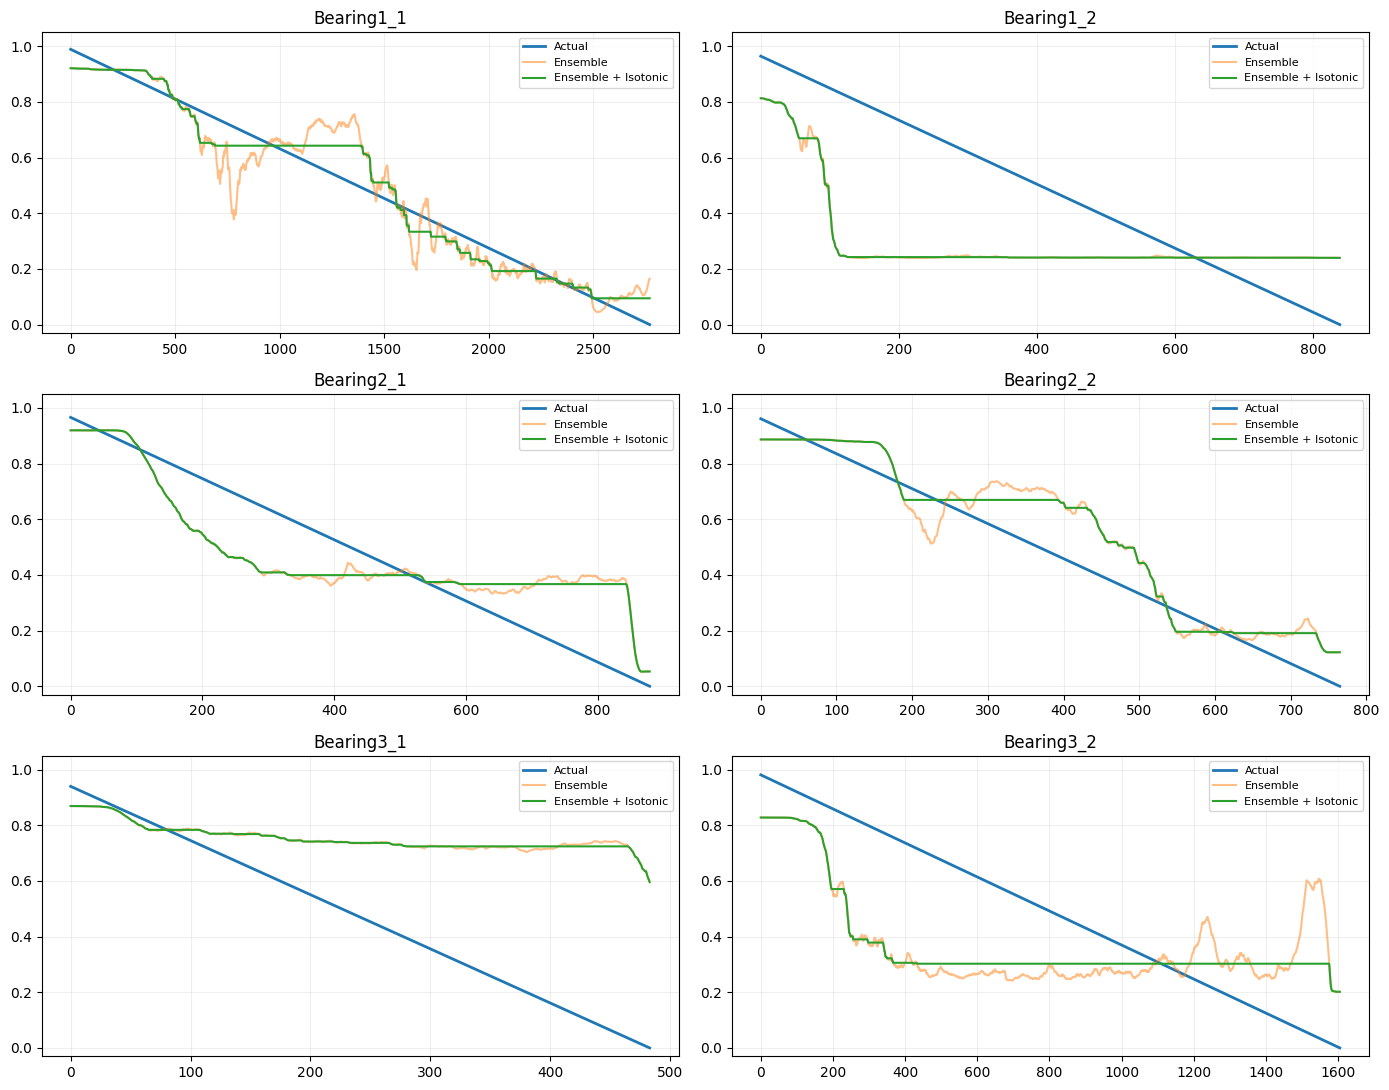


Repeated LOBO experiment completed.
Saved to: /content/bearing_rul_cbam_only/wavelet_fusion_tcn_big/repeated_lobo


In [13]:
import gc
import copy
from sklearn.isotonic import IsotonicRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

REPEAT_SEEDS = [2028, 2045, 2062]
MAX_EPOCHS = 80
PATIENCE = 12

REP = EXP / "repeated_lobo"
REP.mkdir(exist_ok=True)

seed_predictions = {n: {} for n in TRAIN_BEARINGS}
seed_epochs = []
fold_metrics = []

for fold, heldout in enumerate(TRAIN_BEARINGS, 1):

    print(f"\n{'='*55}")
    print(f"Fold {fold}/6: {heldout}")
    print(f"{'='*55}")

    fit_names = [n for n in TRAIN_BEARINGS if n != heldout]

    scaled, scaler = scale_features(
        TRAIN_BEARINGS, fit_names
    )

    train_ds = SequenceDataset(
        scaled, train_labels, fit_names, TRAIN_STRIDE
    )

    sampler = WeightedRandomSampler(
        train_ds.weights, len(train_ds), replacement=True
    )

    train_dl = DataLoader(
        train_ds,
        batch_size=BS,
        sampler=sampler,
        num_workers=0,
        pin_memory=DEVICE.type == "cuda"
    )

    val_ds = SequenceDataset(
        scaled, train_labels, [heldout], 1
    )

    val_dl = DataLoader(
        val_ds, batch_size=256, shuffle=False
    )

    for seed in REPEAT_SEEDS:

        print(f"\nSeed: {seed}")

        torch.manual_seed(seed + fold)
        np.random.seed(seed + fold)
        random.seed(seed + fold)

        if DEVICE.type == "cuda":
            torch.cuda.manual_seed_all(seed + fold)

        model = FusionTCNBiGRU().to(DEVICE)

        optimizer = torch.optim.AdamW(
            model.parameters(),
            lr=4e-4,
            weight_decay=1e-4
        )

        best_mae = float("inf")
        best_state = None
        best_epoch = 1
        wait = 0

        for epoch in range(1, MAX_EPOCHS + 1):

            loss = fit_epoch(model, train_dl, optimizer)

            p, y = predict_dataset(model, val_dl)
            val_mae = mean_absolute_error(y, p)

            if val_mae < best_mae:
                best_mae = val_mae
                best_epoch = epoch
                best_state = {
                    k: v.detach().cpu().clone()
                    for k, v in model.state_dict().items()
                }
                wait = 0
                status = "best"
            else:
                wait += 1
                status = f"wait {wait}/{PATIENCE}"

            if epoch == 1 or epoch % 10 == 0:
                print(
                    f"Epoch {epoch:02d} | "
                    f"loss={loss:.5f} | "
                    f"MAE={val_mae:.5f} | {status}"
                )

            if wait >= PATIENCE:
                break

        model.load_state_dict(best_state)

        p, y = predict_dataset(model, val_dl)

        iso = IsotonicRegression(
            increasing=False,
            y_min=0,
            y_max=1
        )

        pi = iso.fit_transform(np.arange(len(p)), p)

        seed_predictions[heldout][seed] = {
            "actual": y.copy(),
            "raw": p.copy(),
            "isotonic": pi.copy()
        }

        for method, pred in [
            ("Raw", p),
            ("Isotonic", pi)
        ]:
            fold_metrics.append({
                "bearing": heldout,
                "seed": seed,
                "method": method,
                "best_epoch": best_epoch,
                "MAE": mean_absolute_error(y, pred),
                "RMSE": np.sqrt(mean_squared_error(y, pred)),
                "R2": r2_score(y, pred)
            })

        seed_epochs.append({
            "bearing": heldout,
            "seed": seed,
            "best_epoch": best_epoch,
            "best_MAE": best_mae
        })

        torch.save(
            best_state,
            REP / f"{heldout}_{seed}.pt"
        )

        pd.DataFrame(fold_metrics).to_csv(
            REP / "individual_seed_metrics.csv", index=False
        )

        print(
            f"Best epoch: {best_epoch} | "
            f"Raw MAE: {mean_absolute_error(y, p):.5f} | "
            f"Isotonic MAE: {mean_absolute_error(y, pi):.5f}"
        )

        del model, optimizer
        gc.collect()

        if DEVICE.type == "cuda":
            torch.cuda.empty_cache()

    del train_ds, val_ds, train_dl, val_dl
    gc.collect()


# Ensemble held-out predictions

ensemble_rows = []
ensemble_predictions = {}

for n in TRAIN_BEARINGS:

    actual = seed_predictions[n][REPEAT_SEEDS[0]]["actual"]

    raw = np.mean([
        seed_predictions[n][s]["raw"]
        for s in REPEAT_SEEDS
    ], axis=0)

    iso = IsotonicRegression(
        increasing=False, y_min=0, y_max=1
    )

    corrected = iso.fit_transform(
        np.arange(len(raw)), raw
    )

    ensemble_predictions[n] = {
        "actual": actual,
        "raw": raw,
        "isotonic": corrected
    }

    for method, pred in [
        ("Raw ensemble", raw),
        ("Isotonic ensemble", corrected),
        ("Constant 0.5", np.full_like(actual, 0.5))
    ]:
        ensemble_rows.append({
            "bearing": n,
            "method": method,
            "MAE": mean_absolute_error(actual, pred),
            "RMSE": np.sqrt(mean_squared_error(actual, pred)),
            "R2": r2_score(actual, pred)
        })


ensemble_df = pd.DataFrame(ensemble_rows)
individual_df = pd.DataFrame(fold_metrics)

print("\nPER-BEARING ENSEMBLE RESULTS")
display(ensemble_df.round(5))


# Overall metrics

summary_rows = []

for method in ensemble_df.method.unique():

    g = ensemble_df[ensemble_df.method == method]

    col = {
        "Raw ensemble": "raw",
        "Isotonic ensemble": "isotonic",
        "Constant 0.5": None
    }[method]

    actual = np.concatenate([
        ensemble_predictions[n]["actual"]
        for n in TRAIN_BEARINGS
    ])

    if col is None:
        pred = np.full_like(actual, 0.5)
    else:
        pred = np.concatenate([
            ensemble_predictions[n][col]
            for n in TRAIN_BEARINGS
        ])

    summary_rows.append({
        "Model": method,
        "Pooled MAE": mean_absolute_error(actual, pred),
        "Pooled RMSE": np.sqrt(mean_squared_error(actual, pred)),
        "Pooled R2": r2_score(actual, pred),
        "Macro MAE": g.MAE.mean(),
        "Macro RMSE": g.RMSE.mean(),
        "Macro R2": g.R2.mean()
    })


repeat_summary = pd.DataFrame(summary_rows)

print("\nTHREE-SEED LOBO SUMMARY")
display(repeat_summary.round(5))


# Seed-to-seed stability

stability = (
    individual_df[individual_df.method == "Isotonic"]
    .groupby("seed")
    .agg(
        Mean_MAE=("MAE", "mean"),
        Mean_RMSE=("RMSE", "mean"),
        Mean_R2=("R2", "mean")
    )
    .reset_index()
)

print("\nSEED STABILITY")
display(stability.round(5))


# Plots

fig, axes = plt.subplots(3, 2, figsize=(14, 11))

for ax, n in zip(axes.flat, TRAIN_BEARINGS):
    d = ensemble_predictions[n]

    ax.plot(d["actual"], label="Actual", linewidth=2)
    ax.plot(d["raw"], label="Ensemble", alpha=0.5)
    ax.plot(d["isotonic"], label="Ensemble + Isotonic")

    ax.set_title(n)
    ax.set_ylim(-0.03, 1.05)
    ax.grid(alpha=0.2)
    ax.legend(fontsize=8)

plt.tight_layout()
plt.savefig(REP / "repeated_lobo_curves.png", dpi=300)
plt.show()


# Save all results

individual_df.to_csv(
    REP / "individual_seed_metrics.csv", index=False
)

ensemble_df.to_csv(
    REP / "ensemble_per_bearing.csv", index=False
)

repeat_summary.to_csv(
    REP / "ensemble_summary.csv", index=False
)

stability.to_csv(
    REP / "seed_stability.csv", index=False
)

pd.DataFrame(seed_epochs).to_csv(
    REP / "best_epochs.csv", index=False
)

pd.DataFrame([
    {
        "bearing": n,
        "actual": ensemble_predictions[n]["actual"][i],
        "raw": ensemble_predictions[n]["raw"][i],
        "isotonic": ensemble_predictions[n]["isotonic"][i]
    }
    for n in TRAIN_BEARINGS
    for i in range(len(ensemble_predictions[n]["actual"]))
]).to_csv(REP / "ensemble_predictions.csv", index=False)

print("\nRepeated LOBO experiment completed.")
print("Saved to:", REP)

Seed: 2028
Epochs: 8
Epoch 1/8 | loss=0.11307
Epoch 2/8 | loss=0.05297
Epoch 3/8 | loss=0.03108
Epoch 4/8 | loss=0.02051
Epoch 5/8 | loss=0.01623
Epoch 6/8 | loss=0.01346
Epoch 7/8 | loss=0.01164
Epoch 8/8 | loss=0.00961

PER-BEARING RESULTS


,bearing,method,MAE,RMSE,R2
0,Bearing1_3,Raw,0.09025,0.11023,0.85045
1,Bearing1_3,Isotonic,0.08830,0.10954,0.85231
2,Bearing1_4,Raw,0.11040,0.12672,0.79894
3,Bearing1_4,Isotonic,0.11027,0.12494,0.80455
4,Bearing1_5,Raw,0.21640,0.29571,-0.07536
5,Bearing1_5,Isotonic,0.20506,0.27445,0.07367
6,Bearing1_7,Raw,0.26534,0.34527,-0.46931
7,Bearing1_7,Isotonic,0.18784,0.25407,0.20436
8,Bearing2_3,Raw,0.20239,0.25926,0.16808
9,Bearing2_3,Isotonic,0.18179,0.23915,0.29215



FINAL TEST SUMMARY


,Model,Pooled MAE,Pooled RMSE,Pooled R2,Macro MAE,Macro RMSE,Macro R2
0,Raw,0.17732,0.24671,0.24577,0.16662,0.21061,0.34386
1,Isotonic,0.15507,0.21274,0.43916,0.14804,0.18803,0.50315


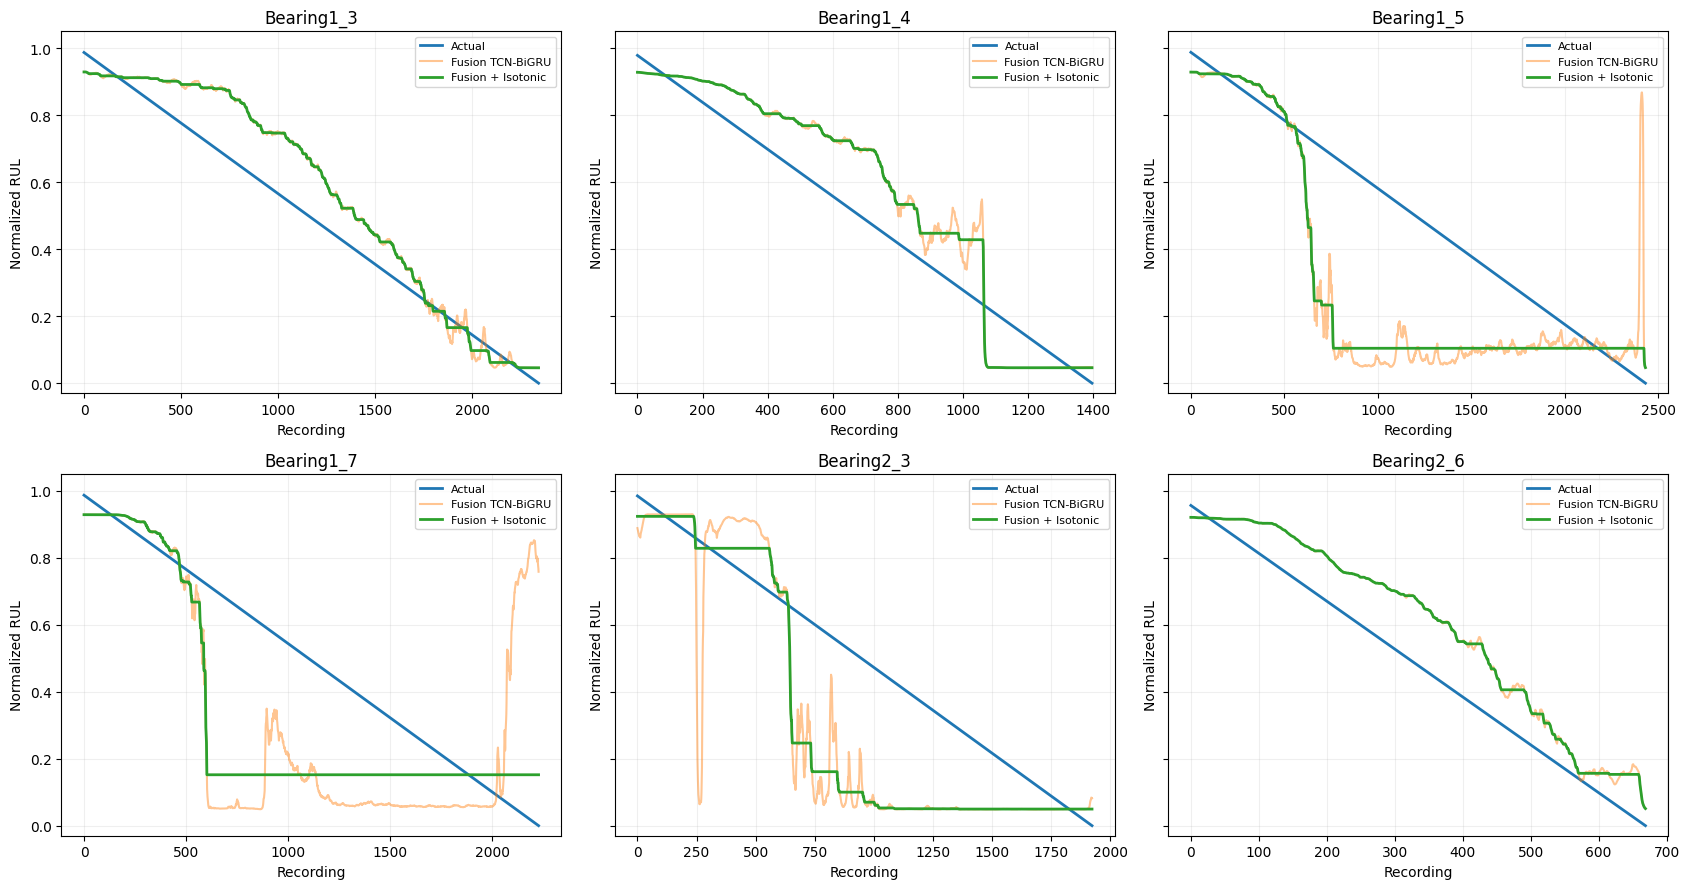

Final model saved to: /content/bearing_rul_cbam_only/wavelet_fusion_tcn_big


In [14]:
import gc
from sklearn.isotonic import IsotonicRegression

FINAL_SEED = 2028
FINAL_EPOCHS = max(
    8, int(np.median([x["best_epoch"] for x in seed_epochs]))
)

print("Seed:", FINAL_SEED)
print("Epochs:", FINAL_EPOCHS)

scaled_all, final_scaler = scale_features(
    TRAIN_BEARINGS + TEST_BEARINGS,
    TRAIN_BEARINGS
)

final_ds = SequenceDataset(
    scaled_all, train_labels,
    TRAIN_BEARINGS, TRAIN_STRIDE
)

sampler = WeightedRandomSampler(
    final_ds.weights, len(final_ds), replacement=True
)

final_dl = DataLoader(
    final_ds,
    batch_size=BS,
    sampler=sampler,
    num_workers=0
)

gc.collect()

if DEVICE.type == "cuda":
    torch.cuda.empty_cache()

torch.manual_seed(FINAL_SEED)
np.random.seed(FINAL_SEED)
random.seed(FINAL_SEED)

model = FusionTCNBiGRU().to(DEVICE)

optimizer = torch.optim.AdamW(
    model.parameters(),
    lr=4e-4,
    weight_decay=1e-4
)

for epoch in range(1, FINAL_EPOCHS + 1):
    loss = fit_epoch(model, final_dl, optimizer)

    print(
        f"Epoch {epoch}/{FINAL_EPOCHS} | "
        f"loss={loss:.5f}"
    )


# Test predictions

test_curves_final = {}
rows = []

for n in TEST_BEARINGS:
    ds = SequenceDataset(
        scaled_all, test_labels, [n], 1
    )

    dl = DataLoader(
        ds, batch_size=256, shuffle=False
    )

    raw, actual = predict_dataset(model, dl)

    iso = IsotonicRegression(
        increasing=False,
        y_min=0,
        y_max=1
    )

    corrected = iso.fit_transform(
        np.arange(len(raw)), raw
    )

    test_curves_final[n] = {
        "actual": actual,
        "raw": raw,
        "isotonic": corrected
    }

    for method, pred in [
        ("Raw", raw),
        ("Isotonic", corrected)
    ]:
        rows.append({
            "bearing": n,
            "method": method,
            "MAE": mean_absolute_error(actual, pred),
            "RMSE": np.sqrt(mean_squared_error(actual, pred)),
            "R2": r2_score(actual, pred)
        })


final_metrics = pd.DataFrame(rows)

summary = []

for method, col in [
    ("Raw", "raw"),
    ("Isotonic", "isotonic")
]:
    actual = np.concatenate([
        test_curves_final[n]["actual"]
        for n in TEST_BEARINGS
    ])

    pred = np.concatenate([
        test_curves_final[n][col]
        for n in TEST_BEARINGS
    ])

    g = final_metrics[final_metrics.method == method]

    summary.append({
        "Model": method,
        "Pooled MAE": mean_absolute_error(actual, pred),
        "Pooled RMSE": np.sqrt(mean_squared_error(actual, pred)),
        "Pooled R2": r2_score(actual, pred),
        "Macro MAE": g.MAE.mean(),
        "Macro RMSE": g.RMSE.mean(),
        "Macro R2": g.R2.mean()
    })

final_summary = pd.DataFrame(summary)

print("\nPER-BEARING RESULTS")
display(final_metrics.round(5))

print("\nFINAL TEST SUMMARY")
display(final_summary.round(5))


# Plot

fig, axes = plt.subplots(2, 3, figsize=(17, 9), sharey=True)

for ax, n in zip(axes.flat, TEST_BEARINGS):
    d = test_curves_final[n]

    ax.plot(d["actual"], label="Actual", linewidth=2)
    ax.plot(d["raw"], label="Fusion TCN-BiGRU", alpha=0.45)
    ax.plot(d["isotonic"], label="Fusion + Isotonic", linewidth=2)

    ax.set_title(n)
    ax.set_xlabel("Recording")
    ax.set_ylabel("Normalized RUL")
    ax.set_ylim(-0.03, 1.05)
    ax.legend(fontsize=8)
    ax.grid(alpha=0.2)

plt.tight_layout()
plt.savefig(EXP / "final_single_seed_test.png", dpi=300)
plt.show()


# Save

torch.save({
    "model_state_dict": {
        k: v.detach().cpu()
        for k, v in model.state_dict().items()
    },
    "seed": FINAL_SEED,
    "epochs": FINAL_EPOCHS
}, EXP / "final_model.pt")

joblib.dump(final_scaler, EXP / "final_scaler.joblib")

final_metrics.to_csv(
    EXP / "final_per_bearing_metrics.csv", index=False
)

final_summary.to_csv(
    EXP / "final_test_summary.csv", index=False
)

pd.DataFrame([
    {
        "bearing": n,
        "actual": test_curves_final[n]["actual"][i],
        "raw": test_curves_final[n]["raw"][i],
        "isotonic": test_curves_final[n]["isotonic"][i]
    }
    for n in TEST_BEARINGS
    for i in range(len(test_curves_final[n]["actual"]))
]).to_csv(EXP / "final_test_predictions.csv", index=False)

print("Final model saved to:", EXP)